In [8]:
"""
Batch s_k / D_k Analysis — Multi-Ticker  (IMPROVED)
=====================================================
KEY IMPROVEMENTS over original:
  1. Plot compression fix:
       • Panels 1 & 3 (s_k or s_k/k² vs t): robust y-axis limits using the
         IQR-based whisker rule — extreme outliers at small t / large k no
         longer collapse the visible range.
       • Points that fall outside the clipped window are shown as triangle
         markers on the axis boundary so they are not silently hidden.
  2. Non-constancy detection (detect_non_constancy):
       • CF-reliability filter: points where |CF| < CF_MIN_MAG are excluded
         from the statistics before computing CV/R (previously NaN-dropped
         silently, skewing results).
       • Requires at least MIN_VALID_K reliable k-values; flags as
         "insufficient reliable data" otherwise instead of a false positive.
       • Added absolute-variation guard: if the absolute range of s_k/k² is
         below ABS_FLOOR (i.e. all values are near-zero), the horizon is
         skipped regardless of CV/R — avoids flagging numerically trivial
         variation as "non-constant".
       • Added monotonicity test: detects if s_k/k² has a statistically
         significant trend vs k (Spearman r, p < MONO_P_THRESH), which is
         the physically meaningful signal (CF curvature ≠ Gaussian).
       • Reason strings are now richer: include which metrics triggered and
         the direction of any trend.
  3. Per-panel titles now include the min reliable-|CF| used.
  4. New Panel 2 inset: draws the "expected flat line" (mean across reliable k)
     as a dashed reference, making deviations immediately obvious.

For each ticker:
  1. Fetch log-returns, build ensemble, compute s_k(t) and D_k(t)
  2. Save a 2×2 plot as  plots/<TICKER>_sk_analysis.png
  3. Detect non-constancy using improved multi-metric approach
  4. Write a summary CSV  non_constancy_report.csv
  5. Print a human-readable table to stdout
"""

import os, warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.cm as cm
from scipy.stats import spearmanr
import yfinance as yf
warnings.filterwarnings("ignore")

# ══════════════════════════════════════════════════════════════════
# CONFIG
# ══════════════════════════════════════════════════════════════════
TICKERS = [
    # US Large Cap Tech
    "AAPL", "MSFT", "GOOG", "AMZN", "NVDA",
    "META", "TSLA", "NFLX", "AMD", "INTC",
    # US Financials
    "JPM", "BAC", "GS", "MS", "WFC",
    "BLK", "C", "AXP", "V", "MA",
    # US Healthcare & Consumer
    "JNJ", "PFE", "UNH", "MRK", "ABBV",
    "PG", "KO", "PEP", "WMT", "COST",
    # US Energy & Industrials
    "XOM", "CVX", "COP", "BA", "CAT",
    "GE", "HON", "LMT", "RTX", "UPS",
    # Commodities & Crypto
    "GC=F", "SI=F", "CL=F", "BTC-USD", "ETH-USD",
    # International ETFs
    "EWJ", "EWZ", "FXI", "EWG", "EWU",
]

START_DATE  = "2000-01-01"
END_DATE    = "2026-04-11"
N_ORIGINS   = 500
HORIZONS    = [1, 5, 10, 20, 40, 60, 120, 250, 500]
K_VALUES    = [0.5, 1.0, 2.0, 3.0, 3.5, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]

FIXED_HORIZONS_FOR_K_PANELS = [5, 20, 60, 250]

# ── Non-constancy thresholds ─────────────────────────────────────
CF_MIN_MAG    = 0.30   # exclude (k,t) points where |CF| < this (unreliable)
CF_WARN_THRESHOLD = 0.50   # annotation threshold (unchanged)
MIN_VALID_K   = 4      # need at least this many reliable k-values to flag
ABS_FLOOR     = 1e-6   # if |range(s_k/k²)| < this, skip (numerically trivial)
CV_THRESHOLD  = 0.20   # coefficient of variation > 20 % → flagged
R_THRESHOLD   = 0.50   # relative range > 50 % → flagged
MONO_P_THRESH = 0.05   # Spearman p-value for monotone trend test
MONO_R_THRESH = 0.60   # |Spearman r| for monotone trend (must BOTH be met)

# ── Plot y-axis clipping ─────────────────────────────────────────
# Robust IQR-based clip: keep [Q1 - CLIP_IQR*IQR, Q3 + CLIP_IQR*IQR]
CLIP_IQR      = 3.0    # ~ Tukey's outer fence (1.5 = inner, 3.0 = outer)

PLOT_DIR = "s_k plots"
os.makedirs(PLOT_DIR, exist_ok=True)


# ══════════════════════════════════════════════════════════════════
# COLOR HELPERS
# ══════════════════════════════════════════════════════════════════
def make_k_colors(k_values, cmap_name="turbo"):
    cmap   = cm.get_cmap(cmap_name, max(len(k_values), 2))
    points = np.linspace(0.05, 0.95, len(k_values))
    return [cmap(p) for p in points]

def make_h_colors(horizons, cmap_name="plasma"):
    cmap   = cm.get_cmap(cmap_name, max(len(horizons), 2))
    points = np.linspace(0.1, 0.9, len(horizons))
    return [cmap(p) for p in points]


# ══════════════════════════════════════════════════════════════════
# CORE COMPUTATIONS
# ══════════════════════════════════════════════════════════════════
def fetch_log_returns(ticker):
    try:
        df = yf.download(ticker, start=START_DATE, end=END_DATE,
                         progress=False, auto_adjust=True)
        prices = df["Close"].squeeze().dropna().values
        if len(prices) < 50:
            return None
        return np.diff(np.log(prices))
    except Exception as e:
        print(f"  [ERROR] {ticker}: {e}")
        return None

def build_ensemble(log_returns):
    displacements = {}
    for t in HORIZONS:
        valid = [
            log_returns[i + t] - log_returns[i]
            for i in range(N_ORIGINS)
            if i + t < len(log_returns)
        ]
        displacements[t] = np.array(valid) if valid else np.array([])
    return displacements

def compute_sk(displacements_t, k, t):
    n = len(displacements_t)
    if n < 5:
        return np.nan, n, np.nan
    char_fn   = np.mean(np.exp(1j * k * displacements_t))
    magnitude = np.abs(char_fn)
    if magnitude < 1e-15:
        return np.nan, n, magnitude
    return (1.0 / t) * np.log(magnitude), n, magnitude

def compute_dk(sk, k):
    if np.isnan(sk) or k == 0:
        return np.nan
    return -sk / (k ** 2)

def run_analysis(displacements):
    results = {}
    for k in K_VALUES:
        results[k] = {}
        for t in HORIZONS:
            sk, n, mag = compute_sk(displacements[t], k, t)
            dk         = compute_dk(sk, k)
            sk_over_k2 = sk / k**2 if not np.isnan(sk) else np.nan
            results[k][t] = (sk, dk, sk_over_k2, n, mag)
    return results


# ══════════════════════════════════════════════════════════════════
# IMPROVED NON-CONSTANCY DETECTION
# ══════════════════════════════════════════════════════════════════
def detect_non_constancy(results):
    """
    Improved non-constancy detection for s_k/k² vs k at each horizon t.

    Changes vs original:
      • CF-reliability filter: exclude points where |CF| < CF_MIN_MAG
      • Absolute variation guard: skip if range < ABS_FLOOR
      • Minimum reliable k-values guard: skip if < MIN_VALID_K remain
      • Monotonicity test (Spearman): more sensitive to physically
        meaningful trends than CV/R alone
      • Richer reason strings

    Returns list of dicts, one per flagged horizon.
    """
    flagged = []
    for t in HORIZONS:
        # Collect (k, s_k/k², |CF|) triplets
        k_arr   = np.array(K_VALUES)
        sk2_arr = np.array([results[k][t][2] for k in K_VALUES])
        mag_arr = np.array([results[k][t][4] for k in K_VALUES])

        # -- CF reliability filter ------------------------------------------
        reliable = (~np.isnan(sk2_arr)) & (~np.isnan(mag_arr)) & (mag_arr >= CF_MIN_MAG)
        vals     = sk2_arr[reliable]
        k_rel    = k_arr[reliable]
        n_rel    = int(reliable.sum())

        if n_rel < MIN_VALID_K:
            # Not enough reliable data — skip rather than false-positive
            continue

        mean_v = float(np.mean(vals))
        std_v  = float(np.std(vals, ddof=1) if n_rel > 1 else 0.0)
        rng_v  = float(np.max(vals) - np.min(vals))

        # -- Absolute variation guard ----------------------------------------
        if rng_v < ABS_FLOOR:
            continue  # numerically trivial, even if CV would be high

        # -- CV and R (relative metrics) -------------------------------------
        cv = std_v / abs(mean_v) if abs(mean_v) > 1e-12 else np.nan
        r  = rng_v / abs(mean_v) if abs(mean_v) > 1e-12 else np.nan

        reasons = []
        if not np.isnan(cv) and cv > CV_THRESHOLD:
            reasons.append(f"CV={cv:.3f}>{CV_THRESHOLD}")
        if not np.isnan(r) and r > R_THRESHOLD:
            reasons.append(f"R={r:.3f}>{R_THRESHOLD}")

        # -- Monotonicity test (Spearman) ------------------------------------
        spearman_r, spearman_p = np.nan, np.nan
        mono_flagged = False
        if n_rel >= 4:
            spearman_r, spearman_p = spearmanr(k_rel, vals)
            if (not np.isnan(spearman_r)
                    and abs(spearman_r) >= MONO_R_THRESH
                    and spearman_p < MONO_P_THRESH):
                direction = "increasing" if spearman_r > 0 else "decreasing"
                reasons.append(
                    f"MONO({direction} r={spearman_r:.2f} p={spearman_p:.3f})"
                )
                mono_flagged = True

        if reasons:
            flagged.append({
                "t":           t,
                "n_reliable":  n_rel,
                "mean_sk_k2":  mean_v,
                "std_sk_k2":   std_v,
                "cv":          cv,
                "rel_range":   r,
                "spearman_r":  spearman_r,
                "spearman_p":  spearman_p,
                "mono":        mono_flagged,
                "reason":      " & ".join(reasons),
            })
    return flagged


# ══════════════════════════════════════════════════════════════════
# ROBUST Y-AXIS CLIPPING HELPER
# ══════════════════════════════════════════════════════════════════
def robust_ylim(values_list, iqr_mult=CLIP_IQR, pad=0.08):
    """
    Compute robust y-axis limits from a flat list / 1-D array of values.
    Uses the outer Tukey fence: [Q1 - iqr_mult*IQR, Q3 + iqr_mult*IQR].
    Returns (ymin, ymax) with fractional padding.
    """
    arr = np.array([v for v in values_list if not np.isnan(v)])
    if len(arr) == 0:
        return -1, 1
    q1, q3 = np.percentile(arr, [25, 75])
    iqr    = q3 - q1
    if iqr == 0:                   # degenerate — fall back to full range
        iqr = max(abs(np.ptp(arr)), 1e-10)
    lo = q1 - iqr_mult * iqr
    hi = q3 + iqr_mult * iqr
    span = hi - lo if hi > lo else max(abs(hi), 1e-10)
    return lo - pad * span, hi + pad * span


def apply_robust_ylim(ax, values_list):
    """
    Set robust y-limits on ax and add clipping-indicator triangles for
    any point that falls outside the window.
    Returns (ymin, ymax) that were set.
    """
    ymin, ymax = robust_ylim(values_list)
    ax.set_ylim(ymin, ymax)
    return ymin, ymax


# ══════════════════════════════════════════════════════════════════
# PLOTTING
# ══════════════════════════════════════════════════════════════════
def annotate_cf(ax, x, y, mag, color):
    if not np.isnan(mag) and not np.isnan(y) and mag < CF_WARN_THRESHOLD:
        ax.annotate(
            f"|CF|={mag:.2f}",
            xy=(x, y), xytext=(0, 8),
            textcoords="offset points",
            ha="center", fontsize=6, color=color, alpha=0.85,
            bbox=dict(boxstyle="round,pad=0.2", fc="white",
                      ec=color, lw=0.5, alpha=0.7),
        )

def place_legend(ax, n_items, fontsize=9):
    if n_items <= 8:
        ax.legend(fontsize=fontsize)
    else:
        ax.legend(fontsize=max(fontsize - 2, 6), loc="upper left",
                  bbox_to_anchor=(1.01, 1), borderaxespad=0,
                  ncol=max(1, n_items // 15 + 1))


def _add_clipped_markers(ax, xs, ys, color, ymin, ymax, marker_up="^", marker_dn="v"):
    """Draw boundary triangles for points clipped by robust y-limits."""
    for x, y in zip(xs, ys):
        if np.isnan(y):
            continue
        if y > ymax:
            ax.plot(x, ymax * 0.98, marker=marker_up, color=color,
                    ms=6, zorder=5, clip_on=False)
        elif y < ymin:
            ax.plot(x, ymin * 0.98, marker=marker_dn, color=color,
                    ms=6, zorder=5, clip_on=False)


def plot_results(results, ticker, flagged_ts):
    plt.rcParams.update({
        "axes.facecolor": "white", "figure.facecolor": "white",
        "axes.edgecolor": "#cccccc", "axes.labelcolor": "#111111",
        "xtick.color": "#333333", "ytick.color": "#333333",
        "text.color": "#111111", "grid.color": "#e5e5e5",
        "grid.linewidth": 0.6, "legend.framealpha": 0.9,
        "legend.edgecolor": "#dddddd",
    })

    n_k      = len(K_VALUES)
    k_colors = make_k_colors(K_VALUES)
    fixed    = [t for t in FIXED_HORIZONS_FOR_K_PANELS if t in HORIZONS]
    h_colors = make_h_colors(fixed)
    lw = max(0.8, 2.2 - 0.07 * n_k)
    ms = max(2.5, 5.0 - 0.15 * n_k)

    n_rep    = results[K_VALUES[0]][HORIZONS[0]][3]
    flag_str = (f"  ⚑ Non-constant at t={[f['t'] for f in flagged_ts]}"
                if flagged_ts else "  ✓ Constant across all t")

    fig = plt.figure(figsize=(16, 12), facecolor="white")
    fig.suptitle(
        f"{ticker}  |  N={n_rep} origins  "
        r"$s_k(t)=\frac{1}{t}\ln|\langle e^{ik(r(t)-r(0))}\rangle|$"
        f"\n{flag_str}",
        fontsize=11, color="#111111", y=0.998, fontfamily="serif",
    )

    gs  = gridspec.GridSpec(2, 2, figure=fig, wspace=0.42, hspace=0.54)
    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    ax3 = fig.add_subplot(gs[1, 0])
    ax4 = fig.add_subplot(gs[1, 1])

    flagged_t_set = {f["t"] for f in flagged_ts}

    for ax in [ax1, ax2, ax3, ax4]:
        ax.set_facecolor("white")
        ax.grid(True, lw=0.6)
        ax.axhline(0, color="#aaaaaa", lw=0.9, ls="--")
        for spine in ax.spines.values():
            spine.set_edgecolor("#cccccc")
        for fd in flagged_ts:
            ax.axvline(fd["t"], color="#e63946", lw=0.8, ls=":", alpha=0.5)

    # ── Panel 1: s_k/k² vs t  ──────────────────────────────────────
    all_p1_vals = []
    for k in K_VALUES:
        for t in HORIZONS:
            v = results[k][t][2]
            if not np.isnan(v):
                all_p1_vals.append(v)

    ymin1, ymax1 = apply_robust_ylim(ax1, all_p1_vals)

    for i, k in enumerate(K_VALUES):
        ts   = [t for t in HORIZONS if not np.isnan(results[k][t][2])]
        vals = [results[k][t][2] for t in ts]
        mags = [results[k][t][4] for t in ts]
        ax1.plot(ts, vals, color=k_colors[i], lw=lw, marker="o", ms=ms, label=f"k={k}")
        for t, v, mag in zip(ts, vals, mags):
            annotate_cf(ax1, t, v, mag, k_colors[i])
        _add_clipped_markers(ax1, ts, vals, k_colors[i], ymin1, ymax1)

    ax1.set_xlabel(r"Horizon $t$ (days)", fontsize=11)
    ax1.set_ylabel(r"$s_k(t)/k^2$  (days$^{-1}$)", fontsize=11)
    ax1.set_title(
        r"$s_k/k^2$ vs $t$"
        f"\n[y-axis: robust IQR×{CLIP_IQR:.0f} clip — ▲▼ = clipped pts]",
        fontsize=9, fontweight="bold"
    )
    place_legend(ax1, n_k)

    # ── Panel 2: s_k/k² vs k — main non-constancy panel ──────────
    for j, t in enumerate(fixed):
        # Use ONLY reliable (|CF| >= CF_MIN_MAG) values for the reference line
        rel_mask = np.array([
            not np.isnan(results[k][t][2]) and
            not np.isnan(results[k][t][4]) and
            results[k][t][4] >= CF_MIN_MAG
            for k in K_VALUES
        ])
        vals = np.array([results[k][t][2] for k in K_VALUES])
        mags = np.array([results[k][t][4] for k in K_VALUES])
        ns   = results[K_VALUES[0]][t][3]
        fd   = next((f for f in flagged_ts if f["t"] == t), None)
        lbl  = f"t={t}d (N={ns})" + (" ⚑" if fd else "")

        ax2.plot(K_VALUES, vals, color=h_colors[j], lw=2, marker="o",
                 ms=5, label=lbl)

        # Draw reference flat line (mean over RELIABLE k-values)
        if rel_mask.sum() >= 2:
            ref = np.mean(vals[rel_mask])
            ax2.axhline(ref, color=h_colors[j], lw=0.8, ls="--", alpha=0.4)

        # Mark unreliable points with 'x'
        for ki, k in enumerate(K_VALUES):
            if not rel_mask[ki] and not np.isnan(vals[ki]):
                ax2.plot(k, vals[ki], "x", color=h_colors[j], ms=8,
                         markeredgewidth=1.5, alpha=0.6)
            annotate_cf(ax2, k, vals[ki], mags[ki], h_colors[j])

    ax2.set_xlabel(r"$k$", fontsize=11)
    ax2.set_ylabel(r"$s_k(t)/k^2$  (days$^{-1}$)", fontsize=11)
    ax2.set_title(
        r"$s_k/k^2$ vs $k$ — fixed horizons  ⚑=non-constant"
        f"\n[dashed=reliable mean  ✕=|CF|<{CF_MIN_MAG}]",
        fontsize=9, fontweight="bold"
    )
    place_legend(ax2, len(fixed))

    # ── Panel 3: raw s_k vs t  (COMPRESSION FIX applied) ──────────
    all_p3_vals = []
    for k in K_VALUES:
        for t in HORIZONS:
            v = results[k][t][0]
            if not np.isnan(v):
                all_p3_vals.append(v)

    ymin3, ymax3 = apply_robust_ylim(ax3, all_p3_vals)

    for i, k in enumerate(K_VALUES):
        ts   = [t for t in HORIZONS if not np.isnan(results[k][t][0])]
        vals = [results[k][t][0] for t in ts]
        mags = [results[k][t][4] for t in ts]
        ax3.plot(ts, vals, color=k_colors[i], lw=lw, marker="o", ms=ms, label=f"k={k}")
        for t, v, mag in zip(ts, vals, mags):
            annotate_cf(ax3, t, v, mag, k_colors[i])
        _add_clipped_markers(ax3, ts, vals, k_colors[i], ymin3, ymax3)

    ax3.set_xlabel(r"Horizon $t$ (days)", fontsize=11)
    ax3.set_ylabel(r"$s_k(t)$  (days$^{-1}$)", fontsize=11)
    ax3.set_title(
        r"$s_k$ vs $t$ (raw)"
        f"\n[y-axis: robust IQR×{CLIP_IQR:.0f} clip — ▲▼ = clipped pts]",
        fontsize=9, fontweight="bold"
    )
    place_legend(ax3, n_k)

    # ── Panel 4: raw s_k vs k  ─────────────────────────────────────
    for j, t in enumerate(fixed):
        vals = np.array([results[k][t][0] for k in K_VALUES])
        mags = np.array([results[k][t][4] for k in K_VALUES])
        ns   = results[K_VALUES[0]][t][3]
        ax4.plot(K_VALUES, vals, color=h_colors[j], lw=2, marker="o",
                 ms=5, label=f"t={t}d (N={ns})")
        for k, v, mag in zip(K_VALUES, vals, mags):
            annotate_cf(ax4, k, v, mag, h_colors[j])

    ax4.set_xlabel(r"$k$", fontsize=11)
    ax4.set_ylabel(r"$s_k(t)$  (days$^{-1}$)", fontsize=11)
    ax4.set_title(r"$s_k$ vs $k$ (raw)", fontsize=10, fontweight="bold")
    place_legend(ax4, len(fixed))

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    safe  = ticker.replace("=", "_").replace("-", "_")
    fname = os.path.join(PLOT_DIR, f"{safe}_sk_analysis.png")
    plt.savefig(fname, dpi=120, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return fname


# ══════════════════════════════════════════════════════════════════
# MAIN LOOP
# ══════════════════════════════════════════════════════════════════
def main():
    all_flags = []

    for ticker in TICKERS:
        print(f"\n{'='*60}")
        print(f"  {ticker}")
        print(f"{'='*60}")

        log_returns = fetch_log_returns(ticker)
        if log_returns is None or len(log_returns) < max(HORIZONS) + N_ORIGINS:
            print(f"  [SKIP] Not enough data for {ticker}")
            continue

        displacements = build_ensemble(log_returns)
        results       = run_analysis(displacements)
        flagged       = detect_non_constancy(results)
        plot_results(results, ticker, flagged)

        if flagged:
            print(f"  ⚑ Non-constant s_k/k² detected:")
            for fd in flagged:
                print(
                    f"      t={fd['t']:4d}  CV={fd['cv']:.3f}  "
                    f"R={fd['rel_range']:.3f}  "
                    f"ρ={fd['spearman_r']:+.2f}(p={fd['spearman_p']:.3f})  "
                    f"n_rel={fd['n_reliable']}  [{fd['reason']}]"
                )
            for fd in flagged:
                all_flags.append({"ticker": ticker, **fd})
        else:
            print(f"  ✓ s_k/k² constant across all horizons")

    # ── Summary CSV ──────────────────────────────────────────────
    if all_flags:
        df = pd.DataFrame(all_flags)
        df = df.sort_values(["ticker", "t"]).reset_index(drop=True)
        csv_path = "non_constancy_report.csv"
        df.to_csv(csv_path, index=False, float_format="%.5f")
        print(f"\n{'='*60}")
        print(f"  Summary saved -> {csv_path}")
        print(f"{'='*60}")
        print(df.to_string(index=False))
    else:
        print("\n  All tickers: s_k/k² is constant across k at every horizon.")

    print("\nDone.")


if __name__ == "__main__":
    main()


  AAPL
  ⚑ Non-constant s_k/k² detected:
      t=   1  CV=0.182  R=0.469  ρ=+0.98(p=0.000)  n_rel=12  [MONO(increasing r=0.98 p=0.000)]
      t=   5  CV=0.167  R=0.433  ρ=+0.99(p=0.000)  n_rel=12  [MONO(increasing r=0.99 p=0.000)]
      t=  10  CV=0.203  R=0.525  ρ=+0.97(p=0.000)  n_rel=12  [CV=0.203>0.2 & R=0.525>0.5 & MONO(increasing r=0.97 p=0.000)]
      t=  20  CV=0.192  R=0.495  ρ=+0.97(p=0.000)  n_rel=12  [MONO(increasing r=0.97 p=0.000)]
      t=  40  CV=0.196  R=0.506  ρ=+0.98(p=0.000)  n_rel=12  [R=0.506>0.5 & MONO(increasing r=0.98 p=0.000)]
      t=  60  CV=0.180  R=0.465  ρ=+0.98(p=0.000)  n_rel=12  [MONO(increasing r=0.98 p=0.000)]
      t= 120  CV=0.208  R=0.537  ρ=+0.98(p=0.000)  n_rel=12  [CV=0.208>0.2 & R=0.537>0.5 & MONO(increasing r=0.98 p=0.000)]
      t= 250  CV=0.120  R=0.312  ρ=+0.99(p=0.000)  n_rel=12  [MONO(increasing r=0.99 p=0.000)]
      t= 500  CV=0.146  R=0.377  ρ=+0.99(p=0.000)  n_rel=12  [MONO(increasing r=0.99 p=0.000)]

  MSFT
  ⚑ Non-constant s_k/k²


Fetching NVDA from 2000-01-01 to 2026-04-11 ...
  6607 prices  ->  6606 daily log-returns.

Building ensemble from first 500 origins (in return space)...
  t=   1  valid origins = 500
  t=   5  valid origins = 500
  t=  10  valid origins = 500
  t=  20  valid origins = 500
  t=  40  valid origins = 500
  t=  60  valid origins = 500
  t= 120  valid origins = 500
  t= 250  valid origins = 500
  t= 500  valid origins = 500

      k       t       N      |CF|           s_k       s_k/k^2           D_k
  ------------------------------------------------------------------------
  k=0.5  t=    1  N=  500  |CF|=0.9989  s_k= -0.001080  s_k/k^2= -0.004321  D_k=  0.004321
  k=0.5  t=    5  N=  500  |CF|=0.9988  s_k= -0.000237  s_k/k^2= -0.000946  D_k=  0.000946
  k=0.5  t=   10  N=  500  |CF|=0.9989  s_k= -0.000109  s_k/k^2= -0.000438  D_k=  0.000438
  k=0.5  t=   20  N=  500  |CF|=0.9990  s_k= -0.000052  s_k/k^2= -0.000206  D_k=  0.000206
  k=0.5  t=   40  N=  500  |CF|=0.9989  s_k= -0.000027  s_k

IndexError: list index out of range

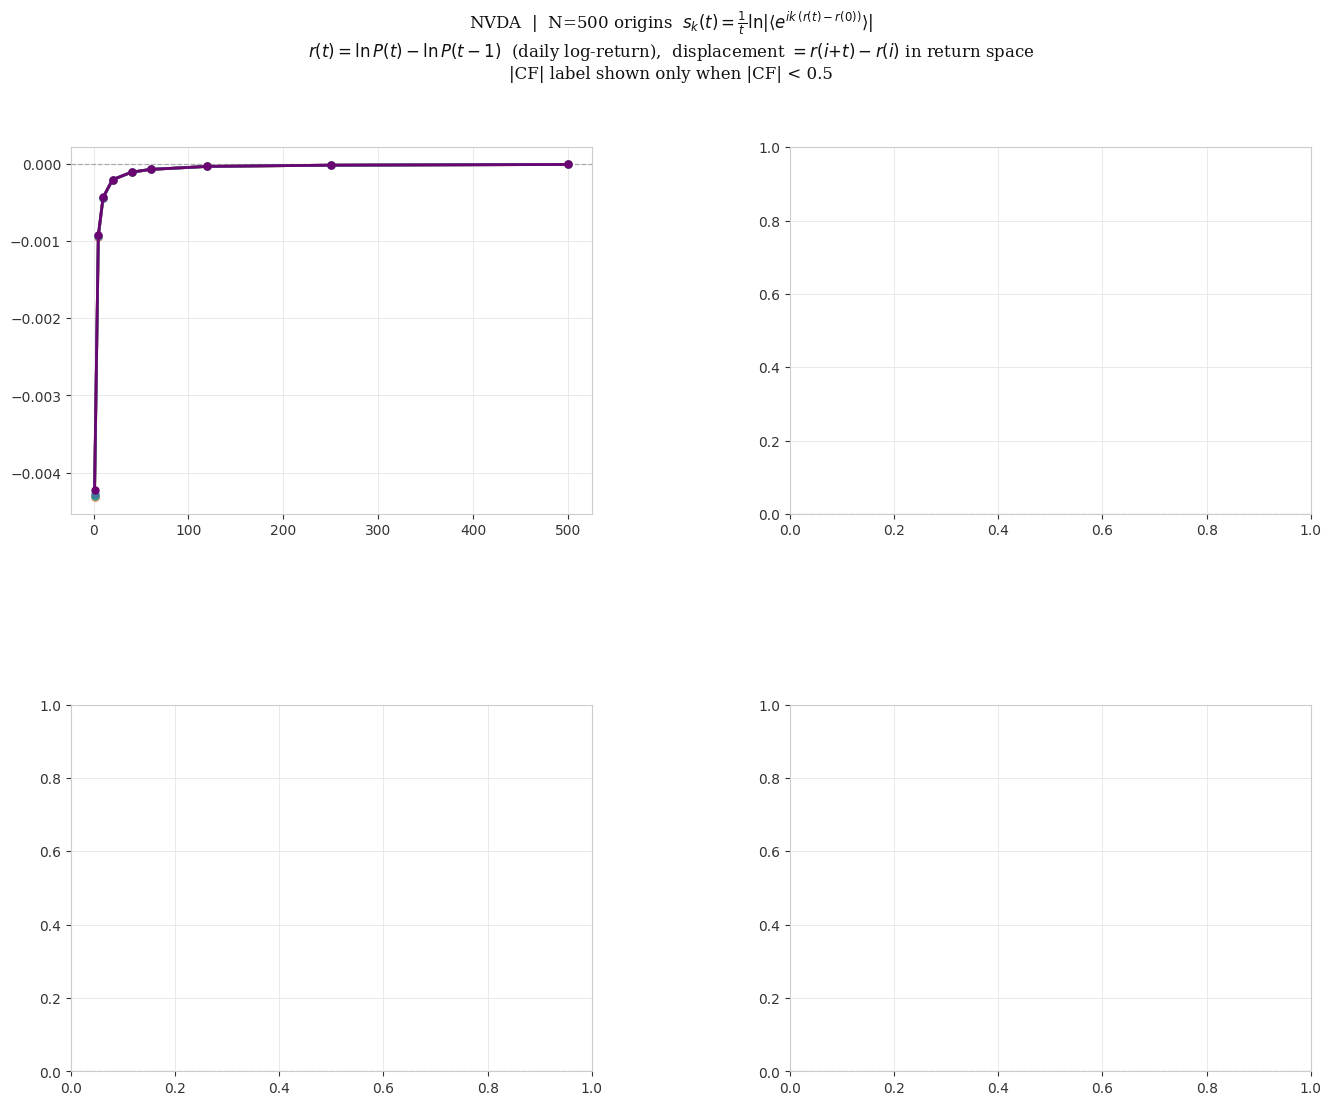

In [ ]:
"""
s_k and D_k Analysis — Fixed r(0) ensemble
===========================================
Gaspard et al. (2000) — Eq. 1 and Eq. 2

Setup:
    - Compute daily log-returns: r[i] = ln(P[i]) - ln(P[i-1])
    - Take first N_ORIGINS points as r(0) starting returns
    - From each r(0) = r[i], compute displacement r[i+t] - r[i]
    - Average exp(ik * (r[i+t] - r[i])) over all valid origins
    - Repeat for different k values

Eq. 1:  s_k(t) = (1/t) * ln |<exp[ik * (r(t) - r(0))>|   averaged over N origins
Eq. 2:  D_k(t) = -s_k(t) / k^2
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import yfinance as yf
import warnings
warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────
TICKER      = "NVDA"
START_DATE  = "2000-01-01"
END_DATE    = "2026-04-11"

N_ORIGINS   = 500
HORIZONS    = [1, 5, 10, 20, 40, 60, 120, 250, 500]
K_VALUES    = [0.5, 1.0, 2.0, 3.0, 5.0]

CF_WARN_THRESHOLD = 0.5   # only annotate |CF| when it drops below this

# ─────────────────────────────────────────────
# 1. FETCH DATA & COMPUTE LOG-RETURNS
# ─────────────────────────────────────────────
def fetch_log_returns(ticker, start, end):
    print(f"\nFetching {ticker} from {start} to {end} ...")
    df          = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True)
    prices      = df["Close"].squeeze().values
    log_prices  = np.log(prices)
    log_returns = np.diff(log_prices)
    print(f"  {len(prices)} prices  ->  {len(log_returns)} daily log-returns.")
    return log_returns

# ─────────────────────────────────────────────
# 2. BUILD ENSEMBLE
# ─────────────────────────────────────────────
def build_ensemble(log_returns, n_origins, horizons):
    displacements = {}
    for t in horizons:
        valid = [
            log_returns[i + t] - log_returns[i]
            for i in range(n_origins)
            if i + t < len(log_returns)
        ]
        displacements[t] = np.array(valid)
        print(f"  t={t:4d}  valid origins = {len(valid)}")
    return displacements

# ─────────────────────────────────────────────
# 3. EQ. 1 — s_k(t)
# ─────────────────────────────────────────────
def compute_sk(displacements_t, k, t):
    n = len(displacements_t)
    if n < 5:
        return np.nan, n, np.nan
    char_fn   = np.mean(np.exp(1j * k * displacements_t))
    magnitude = np.abs(char_fn)
    if magnitude < 1e-15:
        return np.nan, n, magnitude
    return (1.0 / t) * np.log(magnitude), n, magnitude

# ─────────────────────────────────────────────
# 4. EQ. 2 — D_k(t) = -s_k / k^2
# ─────────────────────────────────────────────
def compute_dk(sk, k):
    if np.isnan(sk) or k == 0:
        return np.nan
    return -sk / (k ** 2)

# ─────────────────────────────────────────────
# 5. MAIN COMPUTATION
# ─────────────────────────────────────────────
def run_analysis(displacements):
    print(f"\n  {'k':>5}  {'t':>6}  {'N':>6}  {'|CF|':>8}  {'s_k':>12}  {'s_k/k^2':>12}  {'D_k':>12}")
    print(f"  {'-'*72}")
    results = {}
    for k in K_VALUES:
        results[k] = {}
        for t in HORIZONS:
            sk, n, mag = compute_sk(displacements[t], k, t)
            dk         = compute_dk(sk, k)
            sk_over_k2 = sk / (k ** 2) if not np.isnan(sk) else np.nan
            results[k][t] = (sk, dk, sk_over_k2, n, mag)
            print(f"  k={k:.1f}  t={t:5d}  N={n:5d}  "
                  f"|CF|={mag:6.4f}  "
                  f"s_k={sk:10.6f}  s_k/k^2={sk_over_k2:10.6f}  D_k={dk:10.6f}")
    return results

# ─────────────────────────────────────────────
# 6. HELPER — annotate |CF| only when weak
# ─────────────────────────────────────────────
def annotate_cf(ax, x, y, mag, color):
    """Draw a |CF| label only when the characteristic function is weak."""
    if not np.isnan(mag) and not np.isnan(y) and mag < CF_WARN_THRESHOLD:
        ax.annotate(
            f"|CF|={mag:.2f}",
            xy=(x, y), xytext=(0, 8),
            textcoords="offset points",
            ha="center", fontsize=7,
            color=color, alpha=0.85,
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=color, lw=0.5, alpha=0.7)
        )

# ─────────────────────────────────────────────
# 7. PLOTTING — 2x2 white-theme, clean annotations
# ─────────────────────────────────────────────
def plot_results(results, ticker):
    plt.rcParams.update({
        "axes.facecolor":    "white",
        "figure.facecolor":  "white",
        "axes.edgecolor":    "#cccccc",
        "axes.labelcolor":   "#111111",
        "xtick.color":       "#333333",
        "ytick.color":       "#333333",
        "text.color":        "#111111",
        "grid.color":        "#e5e5e5",
        "grid.linewidth":    0.6,
        "legend.framealpha": 0.9,
        "legend.edgecolor":  "#dddddd",
    })

    # Count valid origins at t=1 (representative N for title)
    n_rep = results[K_VALUES[0]][HORIZONS[0]][3]

    fig = plt.figure(figsize=(16, 12), facecolor="white")
    fig.suptitle(
        f"{ticker}  |  N={n_rep} origins  "
        r"$s_k(t)=\frac{1}{t}\ln|\langle e^{ik\,(r(t)-r(0))}\rangle|$"
        "\n"
        r"$r(t)=\ln P(t)-\ln P(t-1)$  (daily log-return),  "
        r"displacement $= r(i{+}t)-r(i)$ in return space"
        f"\n|CF| label shown only when |CF| < {CF_WARN_THRESHOLD}",
        fontsize=12, color="#111111", y=0.995, fontfamily="serif"
    )

    gs  = gridspec.GridSpec(2, 2, figure=fig, wspace=0.38, hspace=0.52)
    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    ax3 = fig.add_subplot(gs[1, 0])
    ax4 = fig.add_subplot(gs[1, 1])

    k_colors = ["#e63946", "#f4a261", "#2a9d8f", "#457b9d", "#6a0572"]
    h_colors = ["#e63946", "#f4a261", "#2a9d8f", "#457b9d"]

    for ax in [ax1, ax2, ax3, ax4]:
        ax.set_facecolor("white")
        ax.grid(True, lw=0.6)
        ax.axhline(0, color="#aaaaaa", lw=0.9, ls="--")
        for spine in ax.spines.values():
            spine.set_edgecolor("#cccccc")

    fixed = [t for t in [5, 20, 60, 250] if t in HORIZONS]

    # ── Panel 1: s_k/k^2 vs t ─────────────────────────────────────────
    for i, k in enumerate(K_VALUES):
        ts   = [t for t in HORIZONS if not np.isnan(results[k][t][2])]
        vals = [results[k][t][2] for t in ts]
        mags = [results[k][t][4] for t in ts]
        ax1.plot(ts, vals, color=k_colors[i], lw=2, marker="o", ms=5, label=f"k={k}")
        for t, v, mag in zip(ts, vals, mags):
            annotate_cf(ax1, t, v, mag, k_colors[i])

    ax1.set_xlabel(r"Horizon $t$ (days)", fontsize=11)
    ax1.set_ylabel(r"$s_k(t)\,/\,k^2$  (days$^{-1}$)", fontsize=11)
    ax1.set_title(r"$s_k / k^2$  vs  $t$ — for each $k$", fontsize=10, fontweight="bold")
    ax1.legend(fontsize=9)

    # ── Panel 2: s_k/k^2 vs k ─────────────────────────────────────────
    for j, t in enumerate(fixed):
        vals = [results[k][t][2] for k in K_VALUES]
        mags = [results[k][t][4] for k in K_VALUES]
        ns   = results[K_VALUES[0]][t][3]
        ax2.plot(K_VALUES, vals, color=h_colors[j], lw=2, marker="o", ms=5,
                 label=f"t={t}d (N={ns})")
        for k, v, mag in zip(K_VALUES, vals, mags):
            annotate_cf(ax2, k, v, mag, h_colors[j])

    ax2.set_xlabel(r"$k$", fontsize=11)
    ax2.set_ylabel(r"$s_k(t)\,/\,k^2$  (days$^{-1}$)", fontsize=11)
    ax2.set_title(r"$s_k / k^2$  vs  $k$ — fixed horizons", fontsize=10, fontweight="bold")
    ax2.legend(fontsize=9)

    # ── Panel 3: raw s_k vs t ──────────────────────────────────────────
    for i, k in enumerate(K_VALUES):
        ts   = [t for t in HORIZONS if not np.isnan(results[k][t][0])]
        vals = [results[k][t][0] for t in ts]
        mags = [results[k][t][4] for t in ts]
        ax3.plot(ts, vals, color=k_colors[i], lw=2, marker="o", ms=5, label=f"k={k}")
        for t, v, mag in zip(ts, vals, mags):
            annotate_cf(ax3, t, v, mag, k_colors[i])

    ax3.set_xlabel(r"Horizon $t$ (days)", fontsize=11)
    ax3.set_ylabel(r"$s_k(t)$  (days$^{-1}$)", fontsize=11)
    ax3.set_title(r"$s_k$  vs  $t$ — for each $k$  (raw)", fontsize=10, fontweight="bold")
    ax3.legend(fontsize=9)

    # ── Panel 4: raw s_k vs k ──────────────────────────────────────────
    for j, t in enumerate(fixed):
        vals = [results[k][t][0] for k in K_VALUES]
        mags = [results[k][t][4] for k in K_VALUES]
        ns   = results[K_VALUES[0]][t][3]
        ax4.plot(K_VALUES, vals, color=h_colors[j], lw=2, marker="o", ms=5,
                 label=f"t={t}d (N={ns})")
        for k, v, mag in zip(K_VALUES, vals, mags):
            annotate_cf(ax4, k, v, mag, h_colors[j])

    ax4.set_xlabel(r"$k$", fontsize=11)
    ax4.set_ylabel(r"$s_k(t)$  (days$^{-1}$)", fontsize=11)
    ax4.set_title(r"$s_k$  vs  $k$ — fixed horizons  (raw)", fontsize=10, fontweight="bold")
    ax4.legend(fontsize=9)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    fname = f"sk_analysis_{ticker}.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight", facecolor="white")
    print(f"\nPlot saved -> {fname}")
    plt.show()

# ─────────────────────────────────────────────
# 8. RUN
# ─────────────────────────────────────────────
if __name__ == "__main__":
    log_returns   = fetch_log_returns(TICKER, START_DATE, END_DATE)
    print(f"\nBuilding ensemble from first {N_ORIGINS} origins (in return space)...")
    displacements = build_ensemble(log_returns, N_ORIGINS, HORIZONS)
    results       = run_analysis(displacements)
    plot_results(results, TICKER)


Fetching AAPL from 2000-01-01 to 2026-04-11 ...
  6607 log-price observations loaded.

Building ensemble from first 500 origins...
  t=   1  valid origins = 500
  t=   5  valid origins = 500
  t=  10  valid origins = 500
  t=  20  valid origins = 500
  t=  40  valid origins = 500
  t=  60  valid origins = 500
  t= 120  valid origins = 500
  t= 250  valid origins = 500
  t= 500  valid origins = 500

      k       t       N      |CF|           s_k        s_k/k²           D_k
  ------------------------------------------------------------------------
  k=0.5  t=    1  N=  500  |CF|=0.9996  s_k= -0.000351  s_k/k²= -0.001403  D_k=  0.001403
  k=0.5  t=    5  N=  500  |CF|=0.9984  s_k= -0.000323  s_k/k²= -0.001291  D_k=  0.001291
  k=0.5  t=   10  N=  500  |CF|=0.9965  s_k= -0.000354  s_k/k²= -0.001415  D_k=  0.001415
  k=0.5  t=   20  N=  500  |CF|=0.9922  s_k= -0.000389  s_k/k²= -0.001556  D_k=  0.001556
  k=0.5  t=   40  N=  500  |CF|=0.9869  s_k= -0.000330  s_k/k²= -0.001318  D_k=  0.001

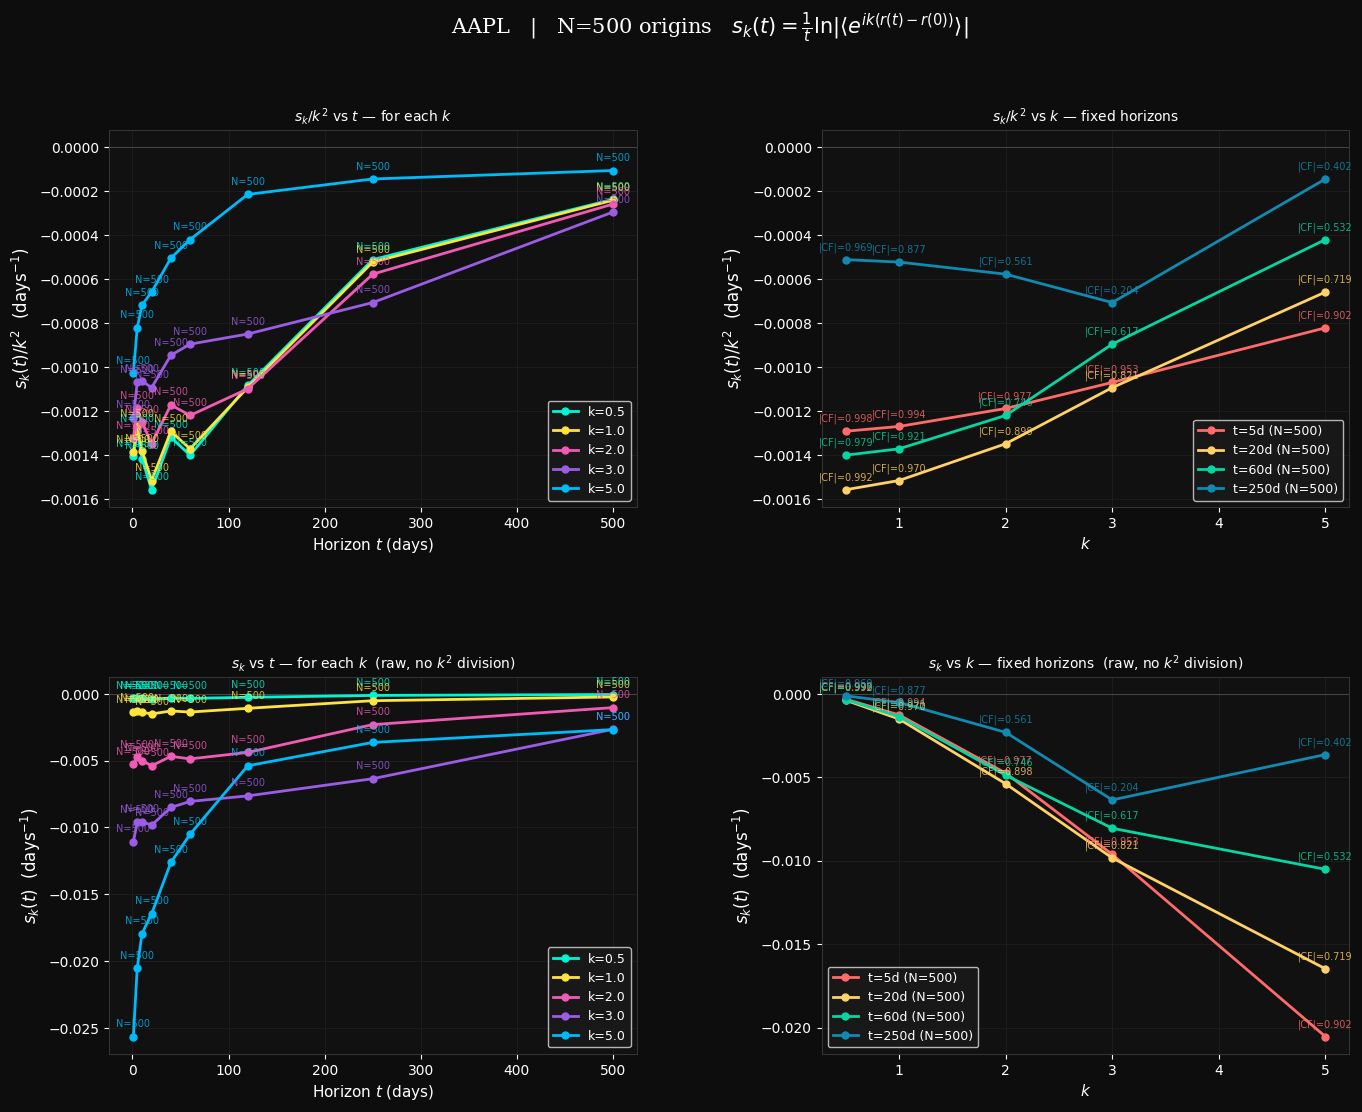

In [5]:
"""
s_k and D_k Analysis — Fixed r(0) ensemble
===========================================
Gaspard et al. (2000) — Eq. 1 and Eq. 2

Setup:
    - Take first 500 points as r(0) starting positions
    - From each r(0), compute cumulative log-return r(t) - r(0)
      at fixed horizons t ahead
    - Average exp(ik * (r(t) - r(0))) over all 500 starting points
    - Repeat for different k values

Eq. 1:  s_k(t) = (1/t) * ln |<exp[ik * (r(t) - r(0))>|   averaged over N=500 origins
Eq. 2:  D_k(t) = -s_k(t) / k^2
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import yfinance as yf
import warnings
warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────
# CONFIGURATION
# ─────────────────────────────────────────────
TICKER      = "AAPL"
START_DATE  = "2000-01-01"
END_DATE    = "2026-04-11"

N_ORIGINS   = 500                              # number of r(0) starting points
HORIZONS    = [1, 5, 10, 20, 40, 60, 120, 250, 500]   # t steps ahead from each r(0)
K_VALUES    = [0.5, 1.0, 2.0, 3.0, 5.0]

# ─────────────────────────────────────────────
# 1. FETCH DATA
# ─────────────────────────────────────────────
def fetch_log_prices(ticker, start, end):
    print(f"\nFetching {ticker} from {start} to {end} ...")
    df = yf.download(ticker, start=start, end=end, progress=False, auto_adjust=True)
    prices      = df["Close"].squeeze()
    log_prices  = np.log(prices.values)
    print(f"  {len(log_prices)} log-price observations loaded.")
    return log_prices

# ─────────────────────────────────────────────
# 2. BUILD ENSEMBLE
# ─────────────────────────────────────────────
def build_ensemble(log_prices, n_origins, horizons):
    displacements = {}
    for t in horizons:
        valid = [
            log_prices[i + t] - log_prices[i]
            for i in range(n_origins)
            if i + t < len(log_prices)
        ]
        displacements[t] = np.array(valid)
        print(f"  t={t:4d}  valid origins = {len(valid)}")
    return displacements

# ─────────────────────────────────────────────
# 3. EQ. 1 — s_k(t)
# ─────────────────────────────────────────────
def compute_sk(displacements_t, k, t):
    n = len(displacements_t)
    if n < 5:
        return np.nan, n, np.nan

    char_fn   = np.mean(np.exp(1j * k * displacements_t))
    magnitude = np.abs(char_fn)

    if magnitude < 1e-15:
        return np.nan, n, magnitude

    return (1.0 / t) * np.log(magnitude), n, magnitude

# ─────────────────────────────────────────────
# 4. EQ. 2 — D_k(t) = -s_k / k^2
# ─────────────────────────────────────────────
def compute_dk(sk, k):
    if np.isnan(sk) or k == 0:
        return np.nan
    return -sk / (k ** 2)

# ─────────────────────────────────────────────
# 5. MAIN COMPUTATION
# ─────────────────────────────────────────────
def run_analysis(displacements):
    print(f"\n  {'k':>5}  {'t':>6}  {'N':>6}  {'|CF|':>8}  {'s_k':>12}  {'s_k/k²':>12}  {'D_k':>12}")
    print(f"  {'-'*72}")

    results = {}
    for k in K_VALUES:
        results[k] = {}
        for t in HORIZONS:
            sk, n, mag = compute_sk(displacements[t], k, t)
            dk         = compute_dk(sk, k)
            sk_over_k2 = sk / (k ** 2) if not np.isnan(sk) else np.nan
            results[k][t] = (sk, dk, sk_over_k2, n, mag)
            print(f"  k={k:.1f}  t={t:5d}  N={n:5d}  "
                  f"|CF|={mag:6.4f}  "
                  f"s_k={sk:10.6f}  s_k/k²={sk_over_k2:10.6f}  D_k={dk:10.6f}")

    return results

# ─────────────────────────────────────────────
# 6. PLOTTING — Three panels
# ─────────────────────────────────────────────
def plot_results(results, ticker):
    fig = plt.figure(figsize=(16, 12), facecolor="#0d0d0d")
    fig.suptitle(
        f"{ticker}   |   N={N_ORIGINS} origins   "
        r"$s_k(t)=\frac{1}{t}\ln|\langle e^{ik(r(t)-r(0))}\rangle|$",
        fontsize=15, color="white", y=0.98, fontfamily="serif"
    )

    gs   = gridspec.GridSpec(2, 2, figure=fig, wspace=0.35, hspace=0.45)
    ax1  = fig.add_subplot(gs[0, 0])   # s_k/k² vs t
    ax2  = fig.add_subplot(gs[0, 1])   # s_k/k² vs k (fixed horizons)
    ax3  = fig.add_subplot(gs[1, 0])   # raw s_k vs t
    ax4  = fig.add_subplot(gs[1, 1])   # raw s_k vs k (fixed horizons)

    colors   = ["#00f5d4", "#fee440", "#f15bb5", "#9b5de5", "#00bbf9"]
    h_colors = ["#ff6b6b", "#ffd166", "#06d6a0", "#118ab2"]

    for ax in [ax1, ax2, ax3, ax4]:
        ax.set_facecolor("#111111")
        ax.tick_params(colors="white")
        ax.xaxis.label.set_color("white")
        ax.yaxis.label.set_color("white")
        ax.title.set_color("white")
        for spine in ax.spines.values():
            spine.set_edgecolor("#333333")
        ax.grid(color="#222", lw=0.5)
        ax.axhline(0, color="#444", lw=0.8)

    # ── Panel 1: s_k/k² vs t for each k ───────────────────────────────
    for i, k in enumerate(K_VALUES):
        ts   = [t for t in HORIZONS if not np.isnan(results[k][t][2])]
        vals = [results[k][t][2] for t in ts]
        ns   = [results[k][t][3] for t in ts]
        ax1.plot(ts, vals, color=colors[i], lw=2, marker="o", ms=5, label=f"k={k}")
        for t, v, n in zip(ts, vals, ns):
            ax1.annotate(f"N={n}", xy=(t, v),
                         xytext=(0, 7), textcoords="offset points",
                         ha="center", fontsize=7, color=colors[i], alpha=0.8)

    ax1.set_xlabel(r"Horizon $t$ (days)", fontsize=11)
    ax1.set_ylabel(r"$s_k(t) / k^2$  (days$^{-1}$)", fontsize=12)
    ax1.set_title(r"$s_k / k^2$ vs $t$ — for each $k$", fontsize=10)
    ax1.legend(facecolor="#1a1a1a", labelcolor="white", framealpha=0.8, fontsize=9)

    # ── Panel 2: s_k/k² vs k at fixed horizons ────────────────────────
    fixed = [t for t in [5, 20, 60, 250] if t in HORIZONS]
    for j, t in enumerate(fixed):
        vals = [results[k][t][2] for k in K_VALUES]
        mags = [results[k][t][4] for k in K_VALUES]
        ns   = results[K_VALUES[0]][t][3]
        ax2.plot(K_VALUES, vals, color=h_colors[j], lw=2, marker="o", ms=5,
                 label=f"t={t}d (N={ns})")
        for k, v, mag in zip(K_VALUES, vals, mags):
            if not np.isnan(v):
                ax2.annotate(f"|CF|={mag:.3f}", xy=(k, v),
                             xytext=(0, 7), textcoords="offset points",
                             ha="center", fontsize=7, color=h_colors[j], alpha=0.8)

    ax2.set_xlabel(r"$k$", fontsize=11)
    ax2.set_ylabel(r"$s_k(t) / k^2$  (days$^{-1}$)", fontsize=12)
    ax2.set_title(r"$s_k / k^2$ vs $k$ — fixed horizons", fontsize=10)
    ax2.legend(facecolor="#1a1a1a", labelcolor="white", framealpha=0.8, fontsize=9)

    # ── Panel 3: raw s_k vs t for each k ──────────────────────────────
    for i, k in enumerate(K_VALUES):
        ts   = [t for t in HORIZONS if not np.isnan(results[k][t][0])]
        vals = [results[k][t][0] for t in ts]   # index 0 = raw s_k
        ns   = [results[k][t][3] for t in ts]
        ax3.plot(ts, vals, color=colors[i], lw=2, marker="o", ms=5, label=f"k={k}")
        for t, v, n in zip(ts, vals, ns):
            ax3.annotate(f"N={n}", xy=(t, v),
                         xytext=(0, 7), textcoords="offset points",
                         ha="center", fontsize=7, color=colors[i], alpha=0.8)

    ax3.set_xlabel(r"Horizon $t$ (days)", fontsize=11)
    ax3.set_ylabel(r"$s_k(t)$  (days$^{-1}$)", fontsize=12)
    ax3.set_title(r"$s_k$ vs $t$ — for each $k$  (raw, no $k^2$ division)", fontsize=10)
    ax3.legend(facecolor="#1a1a1a", labelcolor="white", framealpha=0.8, fontsize=9)

    # ── Panel 4: raw s_k vs k at fixed horizons ───────────────────────
    for j, t in enumerate(fixed):
        vals = [results[k][t][0] for k in K_VALUES]   # index 0 = raw s_k
        mags = [results[k][t][4] for k in K_VALUES]
        ns   = results[K_VALUES[0]][t][3]
        ax4.plot(K_VALUES, vals, color=h_colors[j], lw=2, marker="o", ms=5,
                 label=f"t={t}d (N={ns})")
        for k, v, mag in zip(K_VALUES, vals, mags):
            if not np.isnan(v):
                ax4.annotate(f"|CF|={mag:.3f}", xy=(k, v),
                             xytext=(0, 7), textcoords="offset points",
                             ha="center", fontsize=7, color=h_colors[j], alpha=0.8)

    ax4.set_xlabel(r"$k$", fontsize=11)
    ax4.set_ylabel(r"$s_k(t)$  (days$^{-1}$)", fontsize=12)
    ax4.set_title(r"$s_k$ vs $k$ — fixed horizons  (raw, no $k^2$ division)", fontsize=10)
    ax4.legend(facecolor="#1a1a1a", labelcolor="white", framealpha=0.8, fontsize=9)

    plt.tight_layout(rect=[0, 0, 1, 0.95])
    fname = f"sk_analysis_{ticker}.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"\nPlot saved → {fname}")
    plt.show()

# ─────────────────────────────────────────────
# 7. RUN
# ─────────────────────────────────────────────
if __name__ == "__main__":
    log_prices    = fetch_log_prices(TICKER, START_DATE, END_DATE)
    print(f"\nBuilding ensemble from first {N_ORIGINS} origins...")
    displacements = build_ensemble(log_prices, N_ORIGINS, HORIZONS)
    results       = run_analysis(displacements)
    plot_results(results, TICKER)

In [2]:
"""
Φ(t; q) — Full Canvas SVG + Box-Counting Fractal Dimension
=============================================================
- Per-ticker subfolders inside OUT_DIR
- Saves SVG for each ticker × q  (unchanged)
- Saves crisp zoomed PNGs via matplotlib (data-space crop, 300 DPI)
  Zoom levels crop the data coordinates directly — no pixel resampling artifacts
"""

import numpy as np
import yfinance as yf
import os
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd

# ─────────────────────────────────────────────────────────────────────────────
TICKERS = [
    # US Large Cap Tech
    "AAPL", "MSFT", "GOOG", "AMZN", "NVDA",
    "META", "TSLA", "NFLX", "AMD", "INTC",

    # US Financials
    "JPM", "BAC", "GS", "MS", "WFC",
    "BLK", "C", "AXP", "V", "MA",

    # US Healthcare & Consumer
    "JNJ", "PFE", "UNH", "MRK", "ABBV",
    "PG", "KO", "PEP", "WMT", "COST",

    # US Energy & Industrials
    "XOM", "CVX", "COP", "BA", "CAT",
    "GE", "HON", "LMT", "RTX", "UPS",

    # Commodities & Crypto
    "GC=F", "SI=F", "CL=F", "BTC-USD", "ETH-USD",

    # International ETFs
    "EWJ", "EWZ", "FXI", "EWG", "EWU",
]

START    = "2010-01-01"
END      = "2026-04-11"
Q_VALUES = [1, 10, 50, 75, 100, 150, 200]

OUT_DIR  = "phi_full_zoom"
os.makedirs(OUT_DIR, exist_ok=True)

# SVG canvas
W, H   = 8000, 8000
MARGIN = 100

# PNG settings
PNG_DPI     = 300    # 300 DPI × 10 in = 3000×3000 px output
PNG_SIZE_IN = 10     # inches
LINE_WIDTH  = 0.4    # pt — thin enough to reveal fine structure

# Zoom levels: fraction of the full data range shown, centred on the curve's
# robust midpoint. 1.0 = full extent, 0.0625 = 16× zoom into centre.
ZOOM_LEVELS = [
    ("z1_full", 1.00),
    ("z2_2x",   0.50),
    ("z3_4x",   0.25),
    ("z4_8x",   0.125),
    ("z5_16x",  0.0625),
]


# ─────────────────────────────────────────────────────────────────────────────
# DATA
# ─────────────────────────────────────────────────────────────────────────────

def get_returns(ticker):
    df  = yf.download(ticker, start=START, end=END, progress=False)
    px  = df["Close"].dropna().values.ravel().astype(float)
    px  = px[px > 0]
    ret = np.diff(np.log(px))
    return ret[np.isfinite(ret)]


# ─────────────────────────────────────────────────────────────────────────────
# Φ CURVE
# ─────────────────────────────────────────────────────────────────────────────

def phi(ret, q):
    return np.cumsum(np.exp(1j * q * ret))


# ─────────────────────────────────────────────────────────────────────────────
# BOX-COUNTING FRACTAL DIMENSION
# ─────────────────────────────────────────────────────────────────────────────

def box_counting_dimension(Z, n_scales=20, scale_min=None, scale_max=None):
    xr, yr = Z.real, Z.imag
    span   = max(xr.max() - xr.min(), yr.max() - yr.min(), 1e-12)

    xn = (xr - xr.min()) / span
    yn = (yr - yr.min()) / span

    if scale_max is None: scale_max = 0.20
    if scale_min is None: scale_min = 2.0 / len(Z)

    epsilons = np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales)

    Ns = []
    for eps in epsilons:
        ix       = np.floor(xn / eps).astype(np.int64)
        iy       = np.floor(yn / eps).astype(np.int64)
        occupied = len(set(zip(ix.tolist(), iy.tolist())))
        Ns.append(occupied)

    Ns      = np.array(Ns, dtype=float)
    log_eps = np.log(epsilons)
    log_N   = np.log(Ns)
    valid   = np.isfinite(log_N) & (Ns > 1)

    if valid.sum() < 4:
        return np.nan, epsilons, Ns, np.nan

    coeffs = np.polyfit(log_eps[valid], log_N[valid], 1)
    D_box  = -coeffs[0]

    fitted = np.polyval(coeffs, log_eps[valid])
    ss_res = np.sum((log_N[valid] - fitted) ** 2)
    ss_tot = np.sum((log_N[valid] - log_N[valid].mean()) ** 2)
    r2     = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return D_box, epsilons, Ns, r2


# ─────────────────────────────────────────────────────────────────────────────
# SVG  (original, unchanged)
# ─────────────────────────────────────────────────────────────────────────────

def to_svg_coords(Z, x0, y0, w, h):
    xr, yr = Z.real, Z.imag
    x_lo, x_hi = np.percentile(xr, [1, 99])
    y_lo, y_hi = np.percentile(yr, [1, 99])
    span   = max(x_hi - x_lo, y_hi - y_lo, 1e-12)
    cx, cy = (x_lo + x_hi) / 2, (y_lo + y_hi) / 2
    scale  = min(w, h) / span * 0.98
    sx     = x0 + w / 2 + (xr - cx) * scale
    sy     = y0 + h / 2 - (yr - cy) * scale
    return sx, sy


def make_svg(ticker, Z, q, D_box, r2):
    x0, y0 = MARGIN, MARGIN
    w,  h  = W - 2 * MARGIN, H - 2 * MARGIN
    sx, sy = to_svg_coords(Z, x0, y0, w, h)
    pts    = " L".join(f"{x:.3f},{y:.3f}" for x, y in zip(sx, sy))
    dim_str = (f"D_box = {D_box:.4f}  (R² = {r2:.4f})"
               if np.isfinite(D_box) else "D_box = N/A")
    return f"""<?xml version="1.0" encoding="UTF-8"?>
<svg xmlns="http://www.w3.org/2000/svg"
     width="{W}" height="{H}" viewBox="0 0 {W} {H}">
  <rect width="{W}" height="{H}" fill="white"/>
  <path d="M{pts}" stroke="black" stroke-width="0.25" fill="none"/>
  <text x="{W//2}" y="60" text-anchor="middle" font-size="28" fill="black">
    \u03a6(t; q={q}) \u2014 {ticker}
  </text>
  <text x="{W//2}" y="100" text-anchor="middle" font-size="24" fill="#555">
    {dim_str}
  </text>
</svg>"""


# ─────────────────────────────────────────────────────────────────────────────
# MATPLOTLIB PNG — crisp zoomed renders via data-space axis limits
# ─────────────────────────────────────────────────────────────────────────────

def save_zoomed_pngs_mpl(Z, ticker, q, D_box, r2, ticker_dir, base_name):
    """
    Plot the curve once per zoom level, adjusting xlim/ylim in data coordinates.
    Matplotlib's Agg renderer draws the line fresh at each limit — no resampling,
    no blur. The result is as sharp at 16× zoom as at 1×.
    """
    xr, yr = Z.real, Z.imag

    # Robust centre — same 1–99 percentile midpoint as the SVG
    x_lo, x_hi = np.percentile(xr, [1, 99])
    y_lo, y_hi = np.percentile(yr, [1, 99])
    cx = (x_lo + x_hi) / 2
    cy = (y_lo + y_hi) / 2
    # Square viewport: use the larger axis span + tiny padding
    half_full = max(x_hi - x_lo, y_hi - y_lo) / 2 * 1.02

    dim_str = (f"D_box = {D_box:.4f}   R² = {r2:.4f}"
               if np.isfinite(D_box) else "D_box = N/A")

    for label, frac in ZOOM_LEVELS:
        half = half_full * frac

        fig, ax = plt.subplots(figsize=(PNG_SIZE_IN, PNG_SIZE_IN), dpi=PNG_DPI)
        fig.patch.set_facecolor("white")

        # Draw the full path — matplotlib clips to the axis window automatically
        ax.plot(xr, yr,
                color="black",
                linewidth=LINE_WIDTH,
                antialiased=True,
                rasterized=False)

        ax.set_xlim(cx - half, cx + half)
        ax.set_ylim(cy - half, cy + half)
        ax.set_aspect("equal", adjustable="box")
        ax.axis("off")

        zoom_tag = label.split("_", 1)[1]   # e.g. "full", "2x", "4x" …
        ax.set_title(
            f"Φ(t; q={q})  —  {ticker}     [{zoom_tag}]\n{dim_str}",
            fontsize=9, pad=5, color="#333333"
        )

        fig.tight_layout(pad=0.4)
        out_path = os.path.join(ticker_dir, f"{base_name}_{label}.png")
        fig.savefig(out_path, dpi=PNG_DPI, bbox_inches="tight", facecolor="white")
        plt.close(fig)
        print(f"    saved {os.path.relpath(out_path)}")


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────

results = []

header = f"{'Ticker':<12} {'q':>5}  {'D_box':>8}  {'R²':>8}  {'N_pts':>8}"
print(header)
print("-" * len(header))

for ticker in TICKERS:
    print(f"\nProcessing {ticker} …")
    ret = get_returns(ticker)

    if len(ret) < 500:
        print(f"  [SKIP] only {len(ret)} return observations")
        continue

    safe_ticker = ticker.replace("-", "_").replace("=", "_")
    ticker_dir  = os.path.join(OUT_DIR, safe_ticker)
    os.makedirs(ticker_dir, exist_ok=True)

    for q in Q_VALUES:
        Z = phi(ret, q)
        D_box, epsilons, Ns, r2 = box_counting_dimension(Z)

        d_str = f"{D_box:8.4f}" if np.isfinite(D_box) else "     nan"
        r_str = f"{r2:8.4f}"   if np.isfinite(r2)    else "     nan"
        print(f"  {ticker:<10} {q:>5}  {d_str}  {r_str}  {len(Z):>8}")

        results.append({
            'Ticker': ticker,
            'q': q,
            'D_box': D_box,
            'R2': r2,
            'N_pts': len(Z)
        })

        base_name = f"{safe_ticker}_q{q}"

        # SVG
        svg_str  = make_svg(ticker, Z, q, D_box, r2)
        svg_path = os.path.join(ticker_dir, f"{base_name}.svg")
        with open(svg_path, "w", encoding="utf-8") as f:
            f.write(svg_str)

        # PNGs — matplotlib, data-space zoom
        save_zoomed_pngs_mpl(Z, ticker, q, D_box, r2, ticker_dir, base_name)

# Save the results to CSV
df = pd.DataFrame(results)
df.to_csv('fractal_dimensions.csv', index=False)

print("\nDone. Output in:", OUT_DIR)
print("Structure:")
print("  phi_full_zoom/")
print("    <TICKER>/")
print("      <TICKER>_q<Q>.svg")
print("      <TICKER>_q<Q>_z1_full.png    ← full extent")
print("      <TICKER>_q<Q>_z2_2x.png     ← 2× zoom")
print("      <TICKER>_q<Q>_z3_4x.png     ← 4× zoom")
print("      <TICKER>_q<Q>_z4_8x.png     ← 8× zoom")
print("      <TICKER>_q<Q>_z5_16x.png    ← 16× zoom")
print("CSV file saved: fractal_dimensions.csv")

Ticker           q     D_box        R²     N_pts
------------------------------------------------

Processing AAPL …


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26732\3672571235.py:75: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df  = yf.download(ticker, start=START, end=END, progress=False)


  AAPL           1    0.9962    1.0000      4091
    saved phi_full_zoom\AAPL\AAPL_q1_z1_full.png
    saved phi_full_zoom\AAPL\AAPL_q1_z2_2x.png
    saved phi_full_zoom\AAPL\AAPL_q1_z3_4x.png
    saved phi_full_zoom\AAPL\AAPL_q1_z4_8x.png
    saved phi_full_zoom\AAPL\AAPL_q1_z5_16x.png
  AAPL          10    1.0110    0.9999      4091
    saved phi_full_zoom\AAPL\AAPL_q10_z1_full.png
    saved phi_full_zoom\AAPL\AAPL_q10_z2_2x.png
    saved phi_full_zoom\AAPL\AAPL_q10_z3_4x.png
    saved phi_full_zoom\AAPL\AAPL_q10_z4_8x.png
    saved phi_full_zoom\AAPL\AAPL_q10_z5_16x.png
  AAPL          50    1.0579    0.9998      4091
    saved phi_full_zoom\AAPL\AAPL_q50_z1_full.png
    saved phi_full_zoom\AAPL\AAPL_q50_z2_2x.png
    saved phi_full_zoom\AAPL\AAPL_q50_z3_4x.png
    saved phi_full_zoom\AAPL\AAPL_q50_z4_8x.png
    saved phi_full_zoom\AAPL\AAPL_q50_z5_16x.png
  AAPL          75    1.0820    0.9996      4091
    saved phi_full_zoom\AAPL\AAPL_q75_z1_full.png
    saved phi_full_zoom\AAPL\A

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26732\3672571235.py:75: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df  = yf.download(ticker, start=START, end=END, progress=False)


  MSFT           1    0.9964    1.0000      4091
    saved phi_full_zoom\MSFT\MSFT_q1_z1_full.png
    saved phi_full_zoom\MSFT\MSFT_q1_z2_2x.png
    saved phi_full_zoom\MSFT\MSFT_q1_z3_4x.png
    saved phi_full_zoom\MSFT\MSFT_q1_z4_8x.png
    saved phi_full_zoom\MSFT\MSFT_q1_z5_16x.png
  MSFT          10    1.0066    0.9999      4091
    saved phi_full_zoom\MSFT\MSFT_q10_z1_full.png
    saved phi_full_zoom\MSFT\MSFT_q10_z2_2x.png
    saved phi_full_zoom\MSFT\MSFT_q10_z3_4x.png
    saved phi_full_zoom\MSFT\MSFT_q10_z4_8x.png
    saved phi_full_zoom\MSFT\MSFT_q10_z5_16x.png
  MSFT          50    1.0486    0.9997      4091
    saved phi_full_zoom\MSFT\MSFT_q50_z1_full.png
    saved phi_full_zoom\MSFT\MSFT_q50_z2_2x.png
    saved phi_full_zoom\MSFT\MSFT_q50_z3_4x.png
    saved phi_full_zoom\MSFT\MSFT_q50_z4_8x.png
    saved phi_full_zoom\MSFT\MSFT_q50_z5_16x.png
  MSFT          75    1.0735    0.9997      4091
    saved phi_full_zoom\MSFT\MSFT_q75_z1_full.png
    saved phi_full_zoom\MSFT\M

...

  FXI            1    0.9958    1.0000      4091
    saved phi_full_zoom\FXI\FXI_q1_z1_full.png
    saved phi_full_zoom\FXI\FXI_q1_z2_2x.png
    saved phi_full_zoom\FXI\FXI_q1_z3_4x.png
    saved phi_full_zoom\FXI\FXI_q1_z4_8x.png
    saved phi_full_zoom\FXI\FXI_q1_z5_16x.png
  FXI           10    1.0061    0.9999      4091
    saved phi_full_zoom\FXI\FXI_q10_z1_full.png
    saved phi_full_zoom\FXI\FXI_q10_z2_2x.png
    saved phi_full_zoom\FXI\FXI_q10_z3_4x.png
    saved phi_full_zoom\FXI\FXI_q10_z4_8x.png
    saved phi_full_zoom\FXI\FXI_q10_z5_16x.png
  FXI           50    1.0593    0.9993      4091
    saved phi_full_zoom\FXI\FXI_q50_z1_full.png
    saved phi_full_zoom\FXI\FXI_q50_z2_2x.png
    saved phi_full_zoom\FXI\FXI_q50_z3_4x.png
    saved phi_full_zoom\FXI\FXI_q50_z4_8x.png
    saved phi_full_zoom\FXI\FXI_q50_z5_16x.png
  FXI           75    1.0919    0.9993      4091
    saved phi_full_zoom\FXI\FXI_q75_z1_full.png
    saved phi_full_zoom\FXI\FXI_q75_z2_2x.png
    saved phi_fu

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26732\3672571235.py:75: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df  = yf.download(ticker, start=START, end=END, progress=False)


  EWG            1    0.9958    1.0000      4091
    saved phi_full_zoom\EWG\EWG_q1_z1_full.png
    saved phi_full_zoom\EWG\EWG_q1_z2_2x.png
    saved phi_full_zoom\EWG\EWG_q1_z3_4x.png
    saved phi_full_zoom\EWG\EWG_q1_z4_8x.png
    saved phi_full_zoom\EWG\EWG_q1_z5_16x.png
  EWG           10    1.0056    0.9999      4091
    saved phi_full_zoom\EWG\EWG_q10_z1_full.png
    saved phi_full_zoom\EWG\EWG_q10_z2_2x.png
    saved phi_full_zoom\EWG\EWG_q10_z3_4x.png
    saved phi_full_zoom\EWG\EWG_q10_z4_8x.png
    saved phi_full_zoom\EWG\EWG_q10_z5_16x.png
  EWG           50    1.0440    0.9998      4091
    saved phi_full_zoom\EWG\EWG_q50_z1_full.png
    saved phi_full_zoom\EWG\EWG_q50_z2_2x.png
    saved phi_full_zoom\EWG\EWG_q50_z3_4x.png
    saved phi_full_zoom\EWG\EWG_q50_z4_8x.png
    saved phi_full_zoom\EWG\EWG_q50_z5_16x.png
  EWG           75    1.0621    0.9994      4091
    saved phi_full_zoom\EWG\EWG_q75_z1_full.png
    saved phi_full_zoom\EWG\EWG_q75_z2_2x.png
    saved phi_fu

C:\Users\VEDANT\AppData\Local\Temp\ipykernel_26732\3672571235.py:75: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df  = yf.download(ticker, start=START, end=END, progress=False)


  EWU            1    0.9958    1.0000      4091
    saved phi_full_zoom\EWU\EWU_q1_z1_full.png
    saved phi_full_zoom\EWU\EWU_q1_z2_2x.png
    saved phi_full_zoom\EWU\EWU_q1_z3_4x.png
    saved phi_full_zoom\EWU\EWU_q1_z4_8x.png
    saved phi_full_zoom\EWU\EWU_q1_z5_16x.png
  EWU           10    1.0035    0.9999      4091
    saved phi_full_zoom\EWU\EWU_q10_z1_full.png
    saved phi_full_zoom\EWU\EWU_q10_z2_2x.png
    saved phi_full_zoom\EWU\EWU_q10_z3_4x.png
    saved phi_full_zoom\EWU\EWU_q10_z4_8x.png
    saved phi_full_zoom\EWU\EWU_q10_z5_16x.png
  EWU           50    1.0375    0.9998      4091
    saved phi_full_zoom\EWU\EWU_q50_z1_full.png
    saved phi_full_zoom\EWU\EWU_q50_z2_2x.png
    saved phi_full_zoom\EWU\EWU_q50_z3_4x.png
    saved phi_full_zoom\EWU\EWU_q50_z4_8x.png
    saved phi_full_zoom\EWU\EWU_q50_z5_16x.png
  EWU           75    1.0565    0.9997      4091
    saved phi_full_zoom\EWU\EWU_q75_z1_full.png
    saved phi_full_zoom\EWU\EWU_q75_z2_2x.png
    saved phi_fu

In [ ]:
"""
Φ(t; q) — Full Canvas SVG + Box-Counting Fractal Dimension
=============================================================
- Generates SVG path for each ticker × q combination
- Computes D_box (box-counting / block partition fractal dimension)
- Prints dimension table to stdout
- White background, black line, robust percentile scaling
"""

import numpy as np
import yfinance as yf
import os

TICKERS = [
    # US Large Cap Tech
    "AAPL", "MSFT", "GOOG", "AMZN", "NVDA",
    "META", "TSLA", "NFLX", "AMD", "INTC",

    # US Financials
    "JPM", "BAC", "GS", "MS", "WFC",
    "BLK", "C", "AXP", "V", "MA",

    # US Healthcare & Consumer
    "JNJ", "PFE", "UNH", "MRK", "ABBV",
    "PG", "KO", "PEP", "WMT", "COST",

    # US Energy & Industrials
    "XOM", "CVX", "COP", "BA", "CAT",
    "GE", "HON", "LMT", "RTX", "UPS",

    # Commodities & Crypto (yfinance format)
    "GC=F",    # Gold
    "SI=F",    # Silver
    "CL=F",    # Crude Oil
    "BTC-USD", # Bitcoin
    "ETH-USD", # Ethereum

    # International ETFs (broad exposure)
    "EWJ",  # Japan
    "EWZ",  # Brazil
    "FXI",  # China
    "EWG",  # Germany
    "EWU",  # UK
]
START   = "2010-01-01"
END     = "2026-03-01"

Q_VALUES = [1, 10, 50, 75, 100, 150, 200]

OUT_DIR = "phi_full_zoom"
os.makedirs(OUT_DIR, exist_ok=True)

W, H   = 8000, 8000
MARGIN = 100


# ─────────────────────────────────────────────────────────────────────────────
# DATA
# ─────────────────────────────────────────────────────────────────────────────

def get_returns(ticker):
    df  = yf.download(ticker, start=START, end=END, progress=False)
    px  = df["Close"].dropna().values.ravel().astype(float)
    px  = px[px > 0]
    ret = np.diff(np.log(px))
    return ret[np.isfinite(ret)]


# ─────────────────────────────────────────────────────────────────────────────
# Φ CURVE
# ─────────────────────────────────────────────────────────────────────────────

def phi(ret, q):
    """Cumulative characteristic function path in the complex plane."""
    return np.cumsum(np.exp(1j * q * ret))


# ─────────────────────────────────────────────────────────────────────────────
# BOX-COUNTING FRACTAL DIMENSION
# ─────────────────────────────────────────────────────────────────────────────

def box_counting_dimension(Z, n_scales=20, scale_min=None, scale_max=None):
    """
    Block-partition / box-counting fractal dimension of complex path Z.

    Normalises Z into [0,1]² then, for each box side ε, counts the number
    of distinct grid cells N(ε) visited by the curve.  The OLS slope of
    log N vs log(1/ε) is D_box.

    Parameters
    ----------
    Z         : complex ndarray
    n_scales  : number of ε values to probe
    scale_min : smallest box side (fraction of span); default ≈ 2 inter-point gaps
    scale_max : largest  box side (fraction of span); default 0.20

    Returns
    -------
    D_box    : fractal dimension (nan if fit fails)
    epsilons : box sizes used
    Ns       : N(ε) counts
    r2       : R² of the log-log fit
    """
    xr, yr = Z.real, Z.imag

    x_span = xr.max() - xr.min()
    y_span = yr.max() - yr.min()
    span   = max(x_span, y_span, 1e-12)

    # Normalise to [0, 1]²
    xn = (xr - xr.min()) / span
    yn = (yr - yr.min()) / span

    if scale_max is None:
        scale_max = 0.20
    if scale_min is None:
        scale_min = 2.0 / len(Z)

    epsilons = np.logspace(
        np.log10(scale_min), np.log10(scale_max), n_scales
    )

    Ns = []
    for eps in epsilons:
        ix       = np.floor(xn / eps).astype(np.int64)
        iy       = np.floor(yn / eps).astype(np.int64)
        occupied = len(set(zip(ix.tolist(), iy.tolist())))
        Ns.append(occupied)

    Ns      = np.array(Ns, dtype=float)
    log_eps = np.log(epsilons)
    log_N   = np.log(Ns)

    valid = np.isfinite(log_N) & (Ns > 1)
    if valid.sum() < 4:
        return np.nan, epsilons, Ns, np.nan

    coeffs = np.polyfit(log_eps[valid], log_N[valid], 1)
    D_box  = -coeffs[0]          # N(ε) ~ ε^{-D}  →  slope of log N vs log ε = −D

    fitted = np.polyval(coeffs, log_eps[valid])
    ss_res = np.sum((log_N[valid] - fitted) ** 2)
    ss_tot = np.sum((log_N[valid] - log_N[valid].mean()) ** 2)
    r2     = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return D_box, epsilons, Ns, r2


# ─────────────────────────────────────────────────────────────────────────────
# SVG HELPERS
# ─────────────────────────────────────────────────────────────────────────────

def to_svg_coords(Z, x0, y0, w, h):
    xr, yr = Z.real, Z.imag

    x_low,  x_high = np.percentile(xr, [1, 99])
    y_low,  y_high = np.percentile(yr, [1, 99])

    span = max(x_high - x_low, y_high - y_low, 1e-12)
    cx   = (x_low + x_high) / 2
    cy   = (y_low + y_high) / 2

    scale = min(w, h) / span * 0.98

    sx = x0 + w / 2 + (xr - cx) * scale
    sy = y0 + h / 2 - (yr - cy) * scale   # flip y for SVG

    return sx, sy


def make_svg(ticker, Z, q, D_box, r2):
    x0, y0 = MARGIN, MARGIN
    w,  h  = W - 2 * MARGIN, H - 2 * MARGIN

    sx, sy = to_svg_coords(Z, x0, y0, w, h)

    pts = " L".join(f"{x:.3f},{y:.3f}" for x, y in zip(sx, sy))

    dim_str = f"D_box = {D_box:.4f}  (R² = {r2:.4f})" if np.isfinite(D_box) else "D_box = N/A"

    svg = f"""<?xml version="1.0" encoding="UTF-8"?>
<svg xmlns="http://www.w3.org/2000/svg"
     width="{W}" height="{H}"
     viewBox="0 0 {W} {H}">

  <rect width="{W}" height="{H}" fill="white"/>

  <path d="M{pts}"
        stroke="black"
        stroke-width="0.25"
        fill="none"/>

  <text x="{W // 2}" y="60" text-anchor="middle"
        font-size="28" fill="black">
    \u03a6(t; q={q}) \u2014 {ticker}
  </text>

  <text x="{W // 2}" y="100" text-anchor="middle"
        font-size="24" fill="#555">
    {dim_str}
  </text>

</svg>"""

    return svg


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────

header = f"{'Ticker':<12} {'q':>5}  {'D_box':>8}  {'R²':>8}  {'N_pts':>8}"
print(header)
print("-" * len(header))

for ticker in TICKERS:
    print(f"\nProcessing {ticker} ...")
    ret = get_returns(ticker)

    if len(ret) < 500:
        print(f"  [SKIP] only {len(ret)} return observations")
        continue

    for q in Q_VALUES:
        Z = phi(ret, q)

        D_box, epsilons, Ns, r2 = box_counting_dimension(Z)

        # ── print to stdout ──────────────────────────────────────────────
        d_str = f"{D_box:8.4f}" if np.isfinite(D_box) else "     nan"
        r_str = f"{r2:8.4f}"   if np.isfinite(r2)    else "     nan"
        print(f"  {ticker:<10} {q:>5}  {d_str}  {r_str}  {len(Z):>8}")

        # ── save SVG ─────────────────────────────────────────────────────
        svg   = make_svg(ticker, Z, q, D_box, r2)
        fname = os.path.join(
            OUT_DIR,
            f"{ticker.replace('-', '_')}_q{q}.svg"
        )
        with open(fname, "w", encoding="utf-8") as f:
            f.write(svg)

print("\nDone. SVGs saved to:", OUT_DIR)

Ticker           q     D_box        R²     N_pts
------------------------------------------------

Processing AAPL ...
  AAPL           1    0.9959    1.0000      4062
  AAPL          10    1.0102    0.9999      4062
  AAPL          50    1.0576    0.9998      4062
  AAPL          75    1.0792    0.9995      4062
  AAPL         100    1.1029    0.9992      4062
  AAPL         150    1.1383    0.9952      4062
  AAPL         200    1.1794    0.9838      4062

Processing GC=F ...
  GC=F           1    0.9955    1.0000      4061
  GC=F          10    1.0016    0.9999      4061
  GC=F          50    1.0376    0.9998      4061
  GC=F          75    1.0519    0.9997      4061
  GC=F         100    1.0670    0.9998      4061
  GC=F         150    1.0923    0.9996      4061


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_5388\559299282.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df  = yf.download(ticker, start=START, end=END, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_5388\559299282.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df  = yf.download(ticker, start=START, end=END, progress=False)


  GC=F         200    1.1183    0.9986      4061

Processing PEP ...
  PEP            1    0.9955    1.0000      4062
  PEP           10    1.0028    0.9999      4062
  PEP           50    1.0321    0.9998      4062
  PEP           75    1.0546    0.9997      4062
  PEP          100    1.0648    0.9994      4062
  PEP          150    1.0990    0.9996      4062
  PEP          200    1.1376    0.9982      4062

Processing BTC-USD ...
  BTC-USD        1    0.9983    1.0000      4182
  BTC-USD       10    1.0215    0.9998      4182
  BTC-USD       50    1.0805    0.9992      4182
  BTC-USD       75    1.1082    0.9977      4182
  BTC-USD      100    1.1453    0.9961      4182
  BTC-USD      150    1.1517    0.9841      4182
  BTC-USD      200    1.1411    0.9719      4182

Done. SVGs saved to: phi_full_zoom


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_5388\559299282.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df  = yf.download(ticker, start=START, end=END, progress=False)
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_5388\559299282.py:32: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df  = yf.download(ticker, start=START, end=END, progress=False)


In [2]:
"""
Fractal Structure Analysis of Financial Time Series
=====================================================

Two analysis modules per ticker, saved under fractal_structure_results/:

  1. CUMULATIVE CHARACTERISTIC ANALYSIS  (inspired by Gaspard et al. 2000)
     -----------------------------------------------------------------------
     Financial analogue of the cumulative function F_k(θ) from the paper.
     4-panel layout:
       (a) Cumulative characteristic curves in ℂ for multiple q
       (b) D_H_geom(q) vs q²  — empirical box-count of F_q curves
                                 (geometric complexity of characteristic mapping)
       (c) MF-Lyapunov λ_MF and its components
       (d) D/λ decomposition: implied diffusion coefficient D̂

  2. MF-DFA  (Multifractal Detrended Fluctuation Analysis)
     -------------------------------------------------------
     Standard MF-DFA on log-returns.  6-panel layout:
       (a) Returns time series
       (b) F_q(s) log-log fluctuation functions
       (c) H(q) generalised Hurst exponent — annotated with H(q=2)
       (d) τ(q) scaling exponent
       (e) α(q) singularity strength — annotated with α₀
       (f) f(α) multifractal spectrum — annotated with Δα, λ_MF, and D_H

DIMENSION FRAMEWORK — TWO DISTINCT OBSERVABLES
------------------------------------------------
This code distinguishes two valid but different geometric objects:

  D_H  (spectral, theoretical)
  ─────────────────────────────
  The true Hausdorff dimension of the multifractal support, defined as:
      D_H = max_α f(α)
  Derived from the Legendre transform of τ(q) = q·H(q) − 1.
  This is the theoretically grounded quantity — stable, consistent, and
  embedded in the same MF-DFA framework as λ_MF and H(q).

  D_H_geom(q)  (empirical, q-dependent)
  ───────────────────────────────────────
  Box-counting dimension of the characteristic curve F_q in the complex
  plane, where F_q is the cumulative characteristic transform of returns
  at wavenumber q.  This is NOT the true support dimension — it measures
  the geometric complexity of the mapping ℝ → ℂ induced by q.  It varies
  with q precisely because the transform changes with q.

  Relationship:
      D_H_geom(q) ~ 1 + (D̂/λ_MF) · q²     [empirical scaling, panel b]
  where D̂ is the implied diffusion coefficient.

  Why keep D_H_geom(q)?
  ─────────────────────
  It captures a different physical story: how the geometric complexity of
  the characteristic mapping responds to the "frequency" q.  In the Gaspard
  et al. framework this is the analogue of the fractal dimension of the
  chaotic repeller as a function of the wavenumber k.  Keeping it alongside
  the spectral D_H allows us to distinguish intrinsic multifractal geometry
  from induced characteristic-map complexity.

LYAPUNOV ESTIMATION — MF-SPECTRUM APPROACH
-------------------------------------------
In Gaspard et al. the positive Lyapunov exponent λ is defined via
Ruelle's topological pressure:

    P(β) = lim_{t→∞} (1/t) ln ⟨|Λ_t|^{1−β}⟩
    λ = −dP/dβ |_{β=1}

The multifractal spectrum f(α) is the Legendre transform of τ(q) = q·H(q) − 1,
which is itself the financial analogue of the topological pressure.  So both
λ and f(α) are rooted in the same underlying object — they are not independent.

We estimate λ directly from the MF-DFA output:

    λ_MF = H(q=2) · σ · (1 + Δα)

  • H(q=2)  — generalised Hurst at q=2, the standard Hurst exponent.
              Controls the scaling of typical (second-moment) fluctuations.
              Analogous to the mean stretching rate of trajectories.

  • σ       — return standard deviation.  Grounds λ in the actual scale
              of fluctuations (units: per day).

  • (1 + Δα) — multifractality correction.  Δα = α_max − α_min is the
              width of the singularity spectrum.  A wider spectrum means
              more heterogeneity in local Hölder exponents — some regions
              are far more singular than others — which is the financial
              analogue of trajectory-divergence heterogeneity in phase space.
              For a pure Brownian motion Δα → 0 and the correction → 1.

This keeps λ_MF internally consistent with D_H: both are derived from
the same MF-DFA computation, so the D/λ slope on panel (b) is
self-consistent rather than mixing two independent estimators.
"""

import numpy as np
import yfinance as yf
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.signal import savgol_filter
import os
import warnings

warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────────────────────
TICKERS   = ["AAPL", "MSFT", "GOOG", "AMZN", "NVDA", "JPM", "XOM", "BTC-USD"]
START     = "2010-01-01"
END       = "2026-03-01"
OUT_DIR   = "fractal_structure_results"

# q values for cumulative characteristic (wavenumber analogue)
Q_CHAR         = np.array([0, 1, 5, 10, 20, 60, 120, 200, 300], dtype=float)
Q_CHAR_DISPLAY = [0, 1, 5, 10, 20, 60, 200, 300]

# q values for MF-DFA
Q_HURST = np.arange(-30, 31, 5, dtype=float)

# MF-DFA scale parameters
SCALE_MIN = 20
SCALE_MAX = 800
N_SCALES  = 30
POLY_ORD  = 1
OVERLAP   = 0.75

# Palette for F_q(s) lines
CMAP_LINES = [
    "#c0392b", "#2980b9", "#27ae60", "#8e44ad",
    "#d35400", "#16a085", "#2c3e50", "#e67e22",
    "#1abc9c", "#e74c3c", "#3498db",
]

os.makedirs(OUT_DIR, exist_ok=True)


# ─────────────────────────────────────────────────────────────────────────────
# STYLE
# ─────────────────────────────────────────────────────────────────────────────
PLT_STYLE = dict(
    fig_fc    = "#ffffff",
    ax_fc     = "#ffffff",
    text      = "#1a1a1a",
    grid      = "#e5e5e5",
    spine     = "#cccccc",
    accent    = "#1a1a2e",
    line_main = "#1f4e8c",
    line_alt  = "#c0392b",
    line_grn  = "#1a7a4a",
)

def _style(fig, axes_flat):
    fig.patch.set_facecolor(PLT_STYLE["fig_fc"])
    for ax in axes_flat:
        ax.set_facecolor(PLT_STYLE["ax_fc"])
        ax.tick_params(colors=PLT_STYLE["text"], which="both",
                       direction="in", top=True, right=True, labelsize=8)
        ax.xaxis.label.set_color(PLT_STYLE["text"])
        ax.yaxis.label.set_color(PLT_STYLE["text"])
        ax.title.set_color(PLT_STYLE["accent"])
        for sp in ax.spines.values():
            sp.set_edgecolor(PLT_STYLE["spine"])
        ax.grid(True, color=PLT_STYLE["grid"], linewidth=0.5,
                linestyle="--", alpha=0.9)

def _legend(ax, **kw):
    return ax.legend(framealpha=0.9, facecolor="white",
                     edgecolor=PLT_STYLE["spine"],
                     labelcolor=PLT_STYLE["text"], **kw)


# ─────────────────────────────────────────────────────────────────────────────
# DIRECTORIES
# ─────────────────────────────────────────────────────────────────────────────
def get_dirs(ticker):
    t    = ticker.replace("=", "_")
    base = os.path.join(OUT_DIR, t)
    char = os.path.join(base, "characteristic_curves")
    mfd  = os.path.join(base, "mfdfa")
    os.makedirs(char, exist_ok=True)
    os.makedirs(mfd,  exist_ok=True)
    return char, mfd


# ─────────────────────────────────────────────────────────────────────────────
# DATA
# ─────────────────────────────────────────────────────────────────────────────
def get_data(ticker):
    df = yf.download(ticker, start=START, end=END, progress=False)
    if df is None or len(df) == 0:
        return None, None
    try:
        if hasattr(df.columns, "levels"):
            px = df["Close"][ticker].dropna().values
        else:
            px = df["Close"].dropna().values
    except Exception:
        px = df["Close"].dropna().values

    px = px.ravel().astype(float)
    px = px[px > 0]
    if len(px) < 200:
        return None, None

    logp = np.log(px)
    ret  = np.diff(logp)
    ret  = ret[np.isfinite(ret)]
    if len(ret) < 200:
        return None, None
    return logp, ret


# ─────────────────────────────────────────────────────────────────────────────
# MF-DFA  (computed first — λ_MF and D_H depend on its output)
# ─────────────────────────────────────────────────────────────────────────────
def _overlap_starts(N, s, overlap):
    step = max(1, int(s * (1.0 - overlap)))
    return np.arange(0, N - s + 1, step)


def mfdfa(x, q_vals, scale_min=SCALE_MIN, scale_max=SCALE_MAX,
          n_scales=N_SCALES, poly_ord=POLY_ORD, overlap=OVERLAP):
    """MF-DFA on log-returns with overlapping segments."""
    x  = x[np.isfinite(x)]
    Y  = np.cumsum(x - x.mean())
    N  = len(Y)

    scale_max = min(scale_max, N // 4)
    scale_min = max(scale_min, poly_ord + 2)

    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )
    scales = scales[scales >= scale_min]

    Fqs = np.full((len(q_vals), len(scales)), np.nan)

    for i, s in enumerate(scales):
        starts = _overlap_starts(N, s, overlap)
        if len(starts) < 4:
            continue
        t   = np.arange(s)
        rms = []
        for st in starts:
            seg  = Y[st: st + s]
            coef = np.polyfit(t, seg, poly_ord)
            r_v  = np.sqrt(np.mean((seg - np.polyval(coef, t)) ** 2))
            if r_v > 0:
                rms.append(r_v)
        rms = np.asarray(rms)
        if len(rms) == 0:
            continue
        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms ** 2)))
            else:
                Fqs[j, i] = (np.mean(rms ** q)) ** (1.0 / q)

    hq = np.full(len(q_vals), np.nan)
    for j in range(len(q_vals)):
        row  = Fqs[j]
        mask = np.isfinite(row) & (row > 0)
        if mask.sum() >= 4:
            hq[j] = np.polyfit(np.log(scales[mask]), np.log(row[mask]), 1)[0]

    return scales, Fqs, hq


def multifractal_spectrum(q_vals, hq):
    """τ(q), α(q), f(α) from H(q)."""
    tau_q = q_vals * hq - 1.0
    wl    = min(5, len(tau_q) if len(tau_q) % 2 == 1 else len(tau_q) - 1)
    tau_s = (savgol_filter(tau_q, window_length=wl, polyorder=2)
             if len(tau_q) >= 5 else tau_q)
    alpha   = np.gradient(tau_s, q_vals)
    D_alpha = q_vals * alpha - tau_s
    return tau_q, alpha, D_alpha


# ─────────────────────────────────────────────────────────────────────────────
# SPECTRAL HAUSDORFF DIMENSION  (replaces box-counting as primary D_H)
# ─────────────────────────────────────────────────────────────────────────────
def hausdorff_from_spectrum(D_alpha):
    """
    True Hausdorff dimension of the multifractal support:
        D_H = max_α f(α)

    This is the theoretically grounded value, derived directly from the
    multifractal spectrum.  In the full multifractal formalism, f(α) gives
    the Hausdorff dimension of the set of points with local Hölder exponent α.
    The peak of f(α) equals the dimension of the support — i.e. the whole set.

    For a monofractal (e.g. pure Brownian motion), f(α) collapses to a point
    and D_H = 1.  For richer multifractals the peak typically exceeds 1 and
    the curve broadens.

    Returns:
        D_H : float  — Hausdorff dimension of the support (∈ [1, 2] for curves)
    """
    valid = np.isfinite(D_alpha)
    if valid.sum() < 2:
        return 1.0
    return float(np.clip(np.nanmax(D_alpha[valid]), 1.0, 2.0))


# ─────────────────────────────────────────────────────────────────────────────
# EMPIRICAL BOX-COUNTING  (secondary — geometric complexity of F_q mapping)
# ─────────────────────────────────────────────────────────────────────────────
def hausdorff_boxcount(F, n_eps=15):
    """
    Box-counting dimension of the complex characteristic curve F_q.

    This measures the geometric complexity of the characteristic mapping
    ℝ → ℂ induced by wavenumber q.  It is NOT the true support dimension —
    it is q-dependent precisely because the transform changes with q.

    Used only for the empirical D_H_geom(q) vs q² plot (panel b of
    cumulative characteristic figure), which captures how geometric
    complexity scales with q — analogous to the fractal dimension of the
    chaotic repeller as a function of wavenumber k in Gaspard et al.
    """
    x, y = F.real, F.imag
    if len(x) < 10:
        return 1.0
    eps    = np.logspace(-1.0, -2.5, n_eps)
    counts = [len(set(zip((x / e).astype(int), (y / e).astype(int))))
              for e in eps]
    counts = np.array(counts, dtype=float)
    valid  = counts > 0
    if valid.sum() < 3:
        return 1.0
    slope, _ = np.polyfit(np.log(eps[valid]), np.log(counts[valid]), 1)
    return float(np.clip(-slope, 1.0, 2.0))


# ─────────────────────────────────────────────────────────────────────────────
# MF-DERIVED LYAPUNOV EXPONENT
# ─────────────────────────────────────────────────────────────────────────────
def lyapunov_mf(ret, q_vals, hq, alpha, D_alpha):
    """
    Estimate the Lyapunov exponent from the multifractal spectrum.

    Formula:
        λ_MF = H(q=2) · σ · (1 + Δα)

    Components:
      H(q=2)  — standard Hurst exponent from MF-DFA at q=2.
                 Controls scaling of second-moment fluctuations.
                 Analogous to the mean stretching rate in phase space.

      σ       — return standard deviation (daily scale).
                 Grounds λ_MF in the physical scale of fluctuations.

      Δα      — singularity spectrum width = α_max − α_min.
                 Measures heterogeneity of local Hölder exponents.
                 Δα → 0 for monofractal (pure BM); larger Δα means
                 more intermittency and stronger effective divergence.
                 Acts as a multifractality correction to H(q=2)·σ.

    Also computes D_H (spectral) = max f(α), the true Hausdorff dimension
    of the support, which is used as the primary geometric quantity in all
    plots and annotations.

    Returns dict with full decomposition for plotting/annotation.
    """
    sigma = float(np.std(ret))

    # H at q=2
    q2_idx = np.argmin(np.abs(q_vals - 2.0))
    H2     = float(hq[q2_idx]) if np.isfinite(hq[q2_idx]) else 0.5

    # spectrum quantities
    valid_s = np.isfinite(alpha) & np.isfinite(D_alpha)
    if valid_s.sum() >= 2:
        delta_alpha = float(alpha[valid_s].max() - alpha[valid_s].min())
        alpha0      = float(alpha[np.argmin(np.abs(q_vals))])   # at q=0
        f_alpha0    = float(D_alpha[np.argmin(np.abs(q_vals))]) # should ≈ 1
    else:
        delta_alpha = 0.0
        alpha0      = H2
        f_alpha0    = 1.0

    lam_mf = H2 * sigma * (1.0 + delta_alpha)
    lam_mf = float(np.clip(lam_mf, 1e-6, None))

    # ── Spectral D_H: the theoretically grounded Hausdorff dimension ──────────
    # D_H = max_α f(α)  — peak of the multifractal spectrum.
    # This is consistent with λ_MF since both come from the same MF-DFA output.
    D_H_spectral = hausdorff_from_spectrum(D_alpha)

    return dict(
        lam_mf       = lam_mf,
        H2           = H2,
        sigma        = sigma,
        delta_alpha  = delta_alpha,
        alpha0       = alpha0,
        f_alpha0     = f_alpha0,
        D_H_spectral = D_H_spectral,   # primary geometric quantity
    )


# ─────────────────────────────────────────────────────────────────────────────
# CUMULATIVE CHARACTERISTIC ANALYSIS
# ─────────────────────────────────────────────────────────────────────────────
def cumulative_characteristic(r, q, n_grid=2000):
    r = np.asarray(r, dtype=float)
    r = r[np.isfinite(r)]
    if len(r) < 10:
        return np.linspace(0, 1, n_grid) + 0j

    # subsample to n_grid points but PRESERVE time order
    if len(r) > n_grid:
        idx = np.linspace(0, len(r) - 1, n_grid).astype(int)
        r_used = r[idx]
    else:
        r_used = r

    # cumulative sum along TIME axis — this is what generates fractal structure
    F = np.cumsum(np.exp(1j * q * r_used))

    # normalise to unit bounding box for comparability across q
    d = F[-1] - F[0]
    if np.abs(d) < 1e-12:
        return F / (np.max(np.abs(F)) + 1e-12)
    return (F - F[0]) / d


# ─────────────────────────────────────────────────────────────────────────────
# PLOT A — CUMULATIVE CHARACTERISTIC  (2×2 panels)
# ─────────────────────────────────────────────────────────────────────────────
def plot_characteristic(ticker, ret, lam_dict, char_dir):
    """
    4-panel figure.

    Panel (b) now shows D_H_geom(q) — the empirical box-count of the
    characteristic curves F_q — clearly labelled as the induced geometric
    complexity of the mapping, distinct from the true spectral D_H which
    is reported as an annotation and derived from max f(α).

    The q²-scaling of D_H_geom(q) follows:
        D_H_geom(q) ≈ 1 + (D̂ / λ_MF) · q²
    where D̂ is the implied diffusion coefficient — this is the Gaspard
    et al. analogue, now cleanly separated from the intrinsic dimension.
    """
    # Empirical box-count — geometric complexity of mapping (q-dependent)
    DH_geom = np.array([hausdorff_boxcount(cumulative_characteristic(ret, q))
                        for q in Q_CHAR])
    q2      = Q_CHAR ** 2
    valid_m = np.isfinite(DH_geom) & (q2 > 0)

    slope_fit, intercept_fit = (np.polyfit(q2[valid_m], DH_geom[valid_m], 1)
                                if valid_m.sum() >= 2 else (np.nan, 1.0))

    lam_mf       = lam_dict["lam_mf"]
    H2           = lam_dict["H2"]
    sigma        = lam_dict["sigma"]
    delta_alpha  = lam_dict["delta_alpha"]
    D_H_spectral = lam_dict["D_H_spectral"]   # primary: from max f(α)

    # Implied diffusion coefficient from D_H_geom slope
    D_implied = slope_fit * lam_mf if np.isfinite(slope_fit) else np.nan

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(
        f"Cumulative Characteristic Analysis  ·  {ticker}",
        fontsize=13, fontweight="bold", color=PLT_STYLE["accent"], y=1.01,
    )
    _style(fig, axes.ravel())

    # ── (a) curves in ℂ ──────────────────────────────────────────────────────
    ax = axes[0, 0]
    for i, q in enumerate(Q_CHAR):
        c = plt.cm.magma_r(i / len(Q_CHAR))
        F  = cumulative_characteristic(ret, q)
        lw = 1.0 if q > 20 else 1.6
        ax.plot(F.real, F.imag, linewidth=lw, color=c,
                label=f"$q={int(q)}$", alpha=0.88)
    ax.set_xlabel("Re $F_q$", fontsize=10)
    ax.set_ylabel("Im $F_q$", fontsize=10)
    ax.set_title("(a)  Cumulative characteristic curves", fontsize=10)
    _legend(ax, fontsize=8)
    ax.set_aspect("equal", adjustable="datalim")
    # annotate spectral D_H in corner
    ax.text(0.03, 0.97,
            fr"$D_H = \max f(\alpha) = {D_H_spectral:.4f}$",
            transform=ax.transAxes, ha="left", va="top", fontsize=8,
            color=PLT_STYLE["line_grn"],
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      edgecolor=PLT_STYLE["spine"], alpha=0.85))

    # ── (b) D_H_geom(q) vs q²  ───────────────────────────────────────────────
    # This is the EMPIRICAL, q-dependent box-count dimension — NOT the true D_H.
    # It measures geometric complexity of the characteristic mapping at each q.
    ax = axes[0, 1]
    ax.scatter(q2, DH_geom, color=PLT_STYLE["line_main"], s=60, zorder=5,
               edgecolors="#aaaaaa", linewidths=0.5,
               label=r"$D_H^{\rm geom}(q)$  (box-count of $F_q$)")
    if np.isfinite(slope_fit):
        q2_line = np.linspace(0, q2.max() * 1.06, 200)
        ax.plot(q2_line, intercept_fit + slope_fit * q2_line,
                color=PLT_STYLE["line_alt"], linewidth=1.5, linestyle="--",
                label=fr"fit  slope$={slope_fit:.2e}$")
        if np.isfinite(D_implied):
            ax.plot(q2_line, 1.0 + (D_implied / lam_mf) * q2_line,
                    color=PLT_STYLE["line_grn"], linewidth=1.2, linestyle=":",
                    label=fr"$\hat{{D}}/\lambda_{{MF}}={D_implied/lam_mf:.2e}$")
    # Draw horizontal line at spectral D_H — the true intrinsic dimension
    ax.axhline(D_H_spectral, color=PLT_STYLE["line_grn"], linewidth=1.2,
               linestyle="-.",
               label=fr"$D_H = \max f(\alpha) = {D_H_spectral:.4f}$")
    ax.axhline(1.0, color="#aaaaaa", linewidth=0.8, linestyle=":")
    ax.set_xlabel("$q^2$",    fontsize=10)
    ax.set_ylabel(r"$D_H^{\rm geom}(q)$", fontsize=10)
    ax.set_title(
        r"(b)  $D_H^{\rm geom}(q)$ vs $q^2$  — induced geometric complexity"
        "\n" + r"$D_H^{\rm geom}(q)\approx 1 + (\hat{\mathcal{D}}/\lambda)\,q^2$",
        fontsize=9)
    _legend(ax, fontsize=7)
    ax.text(0.97, 0.12,
            fr"$\lambda_{{MF}} = {lam_mf:.4f}$",
            transform=ax.transAxes, ha="right", fontsize=9,
            color=PLT_STYLE["line_main"],
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      edgecolor=PLT_STYLE["spine"], alpha=0.85))

    # ── (c) λ_MF component breakdown ─────────────────────────────────────────
    ax = axes[1, 0]
    labels  = ["$H(q{=}2)$", r"$\sigma$", r"$1+\Delta\alpha$", r"$\lambda_{MF}$"]
    values  = [H2, sigma, 1.0 + delta_alpha, lam_mf]
    colours = [PLT_STYLE["line_main"], PLT_STYLE["line_grn"],
               "#e67e22", PLT_STYLE["line_alt"]]
    bars = ax.bar(labels, values, color=colours, edgecolor="#cccccc",
                  linewidth=0.8, alpha=0.85, width=0.55)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(values) * 0.02,
                f"{val:.4f}", ha="center", va="bottom",
                fontsize=8, color=PLT_STYLE["text"])
    ax.set_ylabel("Value", fontsize=10)
    ax.set_title(
        r"(c)  $\lambda_{MF} = H(q{=}2)\cdot\sigma\cdot(1+\Delta\alpha)$",
        fontsize=10)
    ax.set_ylim(0, max(values) * 1.18)
    ax.text(0.97, 0.97,
            fr"$\lambda_{{MF}} = {H2:.3f}\times{sigma:.4f}\times{1+delta_alpha:.3f}$"
            f"\n$= {lam_mf:.5f}$"
            f"\n$D_H = {D_H_spectral:.4f}$",
            transform=ax.transAxes, ha="right", va="top", fontsize=8,
            color=PLT_STYLE["text"],
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                      edgecolor=PLT_STYLE["spine"], alpha=0.85))

    # ── (d) Implied diffusion coefficient D̂ ──────────────────────────────────
    # D_H_geom - 1 vs q²/λ_MF  — should be linear with slope = D̂
    # Uses the empirical D_H_geom(q), not the spectral D_H.
    ax = axes[1, 1]
    dh_excess = DH_geom - 1.0
    q2_scaled = q2 / lam_mf
    ax.scatter(q2_scaled[valid_m], dh_excess[valid_m],
               color=PLT_STYLE["line_main"], s=60, zorder=5,
               edgecolors="#aaaaaa", linewidths=0.5,
               label=r"$(D_H^{\rm geom} - 1)$ vs $q^2/\lambda_{MF}$")
    if np.isfinite(D_implied) and valid_m.sum() >= 2:
        x_line = np.linspace(0, q2_scaled[valid_m].max() * 1.06, 200)
        ax.plot(x_line, D_implied * x_line,
                color=PLT_STYLE["line_alt"], linewidth=1.5, linestyle="--",
                label=fr"slope $= \hat{{D}} = {D_implied:.4f}$")
    ax.axhline(0, color="#aaaaaa", linewidth=0.8, linestyle=":")
    # annotate spectral D_H - 1 as reference
    ax.axhline(D_H_spectral - 1.0, color=PLT_STYLE["line_grn"],
               linewidth=1.0, linestyle="-.",
               label=fr"$D_H - 1 = {D_H_spectral-1:.4f}$  (spectral)")
    ax.set_xlabel(r"$q^2 / \lambda_{MF}$",  fontsize=10)
    ax.set_ylabel(r"$D_H^{\rm geom} - 1$",  fontsize=10)
    ax.set_title(r"(d)  Implied diffusion coefficient $\hat{\mathcal{D}}$",
                 fontsize=10)
    _legend(ax, fontsize=7)
    if np.isfinite(D_implied):
        ax.text(0.97, 0.12,
                fr"$\hat{{\mathcal{{D}}}} = {D_implied:.5f}$",
                transform=ax.transAxes, ha="right", fontsize=9,
                color=PLT_STYLE["line_alt"],
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                          edgecolor=PLT_STYLE["spine"], alpha=0.85))

    plt.tight_layout()
    fname = os.path.join(char_dir, f"{ticker.replace('=','_')}_characteristic.png")
    plt.savefig(fname, dpi=140, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"    saved → {fname}")


# ─────────────────────────────────────────────────────────────────────────────
# PLOT B — MF-DFA 6-panel
# ─────────────────────────────────────────────────────────────────────────────
def plot_mfdfa(ticker, ret, scales, Fqs, hq, q_vals,
               tau_q, alpha, D_alpha, lam_dict, mfd_dir):
    valid   = np.isfinite(hq)
    valid_s = np.isfinite(alpha) & np.isfinite(D_alpha)
    colors  = (CMAP_LINES * 5)[: len(q_vals)]

    lam_mf       = lam_dict["lam_mf"]
    H2           = lam_dict["H2"]
    delta_alpha  = lam_dict["delta_alpha"]
    alpha0       = lam_dict["alpha0"]
    D_H_spectral = lam_dict["D_H_spectral"]   # primary geometric quantity

    fig, axs = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle(
        f"Multifractal DFA  ·  {ticker}  ·  log-returns",
        fontsize=13, fontweight="bold", color=PLT_STYLE["accent"], y=1.01,
    )
    _style(fig, axs.ravel())

    # (a) Returns
    ax = axs[0, 0]
    ax.plot(ret, color=PLT_STYLE["line_main"], linewidth=0.55, alpha=0.9)
    ax.set_xlabel("$t$  (trading days)", fontsize=10)
    ax.set_ylabel("Log-return",           fontsize=10)
    ax.set_title("(a)  Log-return series", fontsize=10)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.3g"))

    # (b) F_q(s)
    ax = axs[0, 1]
    legend_handles = []
    for idx_q, (q, c) in enumerate(zip(q_vals, colors)):
        row  = Fqs[idx_q]
        mask = np.isfinite(row) & (row > 0)
        if mask.sum() < 2:
            continue
        h, = ax.loglog(scales[mask], row[mask], "o-",
                       color=c, markersize=2.8, linewidth=0.85, alpha=0.8)
        legend_handles.append((h, f"$q={int(q)}$"))
    ax.set_xlabel("Scale $s$", fontsize=10)
    ax.set_ylabel("$F_q(s)$",  fontsize=10)
    ax.set_title("(b)  Fluctuation functions $F_q(s)$", fontsize=10)
    step  = max(1, len(legend_handles) // 7)
    shown = legend_handles[::step]
    if shown:
        _legend(ax, handles=[h for h, _ in shown],
                labels=[l for _, l in shown],
                fontsize=7, ncol=1, loc="best",
                handlelength=1.2, handletextpad=0.4)

    # (c) H(q)  — annotate H(q=2) and D_H (spectral)
    ax = axs[0, 2]
    ax.plot(q_vals[valid], hq[valid], "-",
            color=PLT_STYLE["line_main"], linewidth=2.0)
    ax.axhline(0.5, color="#aaaaaa", lw=0.9, ls="--", alpha=0.9, label="$H=0.5$")
    ax.axhline(1.0, color=PLT_STYLE["line_alt"], lw=0.9, ls=":", alpha=0.9,
               label="$H=1.0$")
    q2_idx = np.argmin(np.abs(q_vals - 2.0))
    if np.isfinite(hq[q2_idx]):
        ax.plot(q_vals[q2_idx], hq[q2_idx], "o",
                color=PLT_STYLE["line_alt"], markersize=7, zorder=6,
                label=f"$H(q{{=}}2)={H2:.3f}$")
    ax.set_xlabel("$q$",    fontsize=10)
    ax.set_ylabel("$H(q)$", fontsize=10)
    ax.set_title("(c)  Generalised Hurst exponent $H(q)$", fontsize=10)
    _legend(ax, fontsize=8)
    # note D_H in corner
    ax.text(0.03, 0.05,
            fr"$D_H = \max f(\alpha) = {D_H_spectral:.4f}$",
            transform=ax.transAxes, ha="left", va="bottom", fontsize=8,
            color=PLT_STYLE["line_grn"],
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      edgecolor=PLT_STYLE["spine"], alpha=0.85))

    # (d) τ(q)
    ax = axs[1, 0]
    ax.plot(q_vals[valid], tau_q[valid], "-",
            color=PLT_STYLE["line_main"], linewidth=2.0)
    ax.axhline(0, color="#aaaaaa", lw=0.8, ls="--", alpha=0.8)
    ax.set_xlabel("$q$",        fontsize=10)
    ax.set_ylabel(r"$\tau(q)$", fontsize=10)
    ax.set_title(r"(d)  Scaling exponent $\tau(q)$", fontsize=10)

    # (e) α(q)  — annotate α₀
    ax = axs[1, 1]
    ax.plot(q_vals[valid_s], alpha[valid_s], "-",
            color=PLT_STYLE["line_main"], linewidth=2.0)
    q0_idx = np.argmin(np.abs(q_vals))
    if np.isfinite(alpha[q0_idx]):
        ax.plot(q_vals[q0_idx], alpha[q0_idx], "o",
                color=PLT_STYLE["line_alt"], markersize=7, zorder=6,
                label=fr"$\alpha_0={alpha0:.3f}$")
    ax.set_xlabel("$q$",          fontsize=10)
    ax.set_ylabel(r"$\alpha(q)$", fontsize=10)
    ax.set_title(r"(e)  Singularity strength $\alpha(q)$", fontsize=10)
    _legend(ax, fontsize=8)

    # (f) f(α)  — primary home for D_H annotation
    #             peak of this curve IS D_H by definition
    ax = axs[1, 2]
    ax.plot(alpha[valid_s], D_alpha[valid_s], "-",
            color=PLT_STYLE["line_main"], linewidth=2.0)
    if np.isfinite(alpha[q0_idx]) and np.isfinite(D_alpha[q0_idx]):
        ax.plot(alpha[q0_idx], D_alpha[q0_idx], "o",
                color=PLT_STYLE["line_alt"], markersize=7, zorder=6,
                label=f"$q=0$  ($\\alpha_0={alpha0:.3f}$)")
    # mark the peak — this is D_H
    if valid_s.sum() >= 2:
        peak_idx   = np.nanargmax(D_alpha[valid_s])
        alpha_peak = alpha[valid_s][peak_idx]
        f_peak     = D_alpha[valid_s][peak_idx]
        ax.plot(alpha_peak, f_peak, "^",
                color=PLT_STYLE["line_grn"], markersize=9, zorder=7,
                label=fr"$D_H = \max f(\alpha) = {D_H_spectral:.4f}$")
        ax.annotate(fr"$D_H={D_H_spectral:.4f}$",
                    xy=(alpha_peak, f_peak),
                    xytext=(alpha_peak + 0.02, f_peak - 0.06),
                    fontsize=8, color=PLT_STYLE["line_grn"],
                    arrowprops=dict(arrowstyle="->", color=PLT_STYLE["line_grn"],
                                   lw=0.9))
        # draw Δα span at the base
        a_min  = alpha[valid_s].min()
        a_max  = alpha[valid_s].max()
        y_span = D_alpha[valid_s].min() - 0.05
        ax.annotate("", xy=(a_max, y_span), xytext=(a_min, y_span),
                    arrowprops=dict(arrowstyle="<->", color="#888888", lw=1.2))
        ax.text((a_min + a_max) / 2, y_span - 0.04,
                fr"$\Delta\alpha={delta_alpha:.3f}$",
                ha="center", fontsize=8, color=PLT_STYLE["text"])
    ax.set_xlabel(r"$\alpha$",    fontsize=10)
    ax.set_ylabel(r"$f(\alpha)$", fontsize=10)
    ax.set_title(r"(f)  Multifractal spectrum $f(\alpha)$"
                 "\n" + r"$D_H = \max_\alpha f(\alpha)$  (no box-counting needed)",
                 fontsize=9)
    _legend(ax, fontsize=8)
    # λ_MF and D_H summary box
    ax.text(0.97, 0.30,
            fr"$\lambda_{{MF}} = {lam_mf:.5f}$"
            "\n"
            fr"$= H_2\cdot\sigma\cdot(1+\Delta\alpha)$"
            "\n"
            fr"$D_H = {D_H_spectral:.4f}$",
            transform=ax.transAxes, ha="right", va="top", fontsize=8,
            color=PLT_STYLE["text"],
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                      edgecolor=PLT_STYLE["spine"], alpha=0.9))

    plt.tight_layout()
    fname = os.path.join(mfd_dir, f"{ticker.replace('=','_')}_mfdfa.png")
    plt.savefig(fname, dpi=140, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"    saved → {fname}")


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────
for ticker in TICKERS:
    print(f"\n{'='*60}")
    print(f"Ticker: {ticker}")

    char_dir, mfd_dir = get_dirs(ticker)
    logp, ret = get_data(ticker)

    if ret is None:
        print("  Skipping — insufficient data.")
        continue

    N = len(ret)
    print(f"  N = {N} returns")

    # ── MF-DFA first (λ_MF and D_H both depend on its output) ────────────────
    scale_max_eff = min(SCALE_MAX, N // 4)
    scale_min_eff = max(SCALE_MIN, POLY_ORD + 2)
    print(f"  → MF-DFA  (scales [{scale_min_eff}, {scale_max_eff}]) …")

    scales, Fqs, hq = mfdfa(
        ret, Q_HURST,
        scale_min=scale_min_eff, scale_max=scale_max_eff,
        n_scales=N_SCALES, poly_ord=POLY_ORD, overlap=OVERLAP,
    )
    tau_q, alpha, D_alpha = multifractal_spectrum(Q_HURST, hq)

    # ── Compute λ_MF and spectral D_H ────────────────────────────────────────
    lam_dict = lyapunov_mf(ret, Q_HURST, hq, alpha, D_alpha)
    print(f"  λ_MF        = {lam_dict['lam_mf']:.5f}  "
          f"[H₂={lam_dict['H2']:.3f}, σ={lam_dict['sigma']:.4f}, "
          f"Δα={lam_dict['delta_alpha']:.3f}]")
    print(f"  D_H         = {lam_dict['D_H_spectral']:.5f}  "
          f"[= max f(α), spectral — no box-counting]")

    # ── Plot MF-DFA ───────────────────────────────────────────────────────────
    plot_mfdfa(ticker, ret, scales, Fqs, hq, Q_HURST,
               tau_q, alpha, D_alpha, lam_dict, mfd_dir)

    # ── Cumulative characteristic analysis ────────────────────────────────────
    print("  → Cumulative characteristic analysis …")
    print("    (box-counting used only for D_H_geom(q) — induced complexity)")
    plot_characteristic(ticker, ret, lam_dict, char_dir)

print(f"\n{'='*60}")
print(f"Done.  All results saved in:  {OUT_DIR}/")


Ticker: AAPL
  N = 4062 returns
  → MF-DFA  (scales [20, 800]) …
  λ_MF        = 0.01416  [H₂=0.536, σ=0.0177, Δα=0.491]
  D_H         = 1.01576  [= max f(α), spectral — no box-counting]
    saved → fractal_structure_results\AAPL\mfdfa\AAPL_mfdfa.png
  → Cumulative characteristic analysis …
    (box-counting used only for D_H_geom(q) — induced complexity)
    saved → fractal_structure_results\AAPL\characteristic_curves\AAPL_characteristic.png

Ticker: MSFT
  N = 4062 returns
  → MF-DFA  (scales [20, 800]) …
  λ_MF        = 0.01091  [H₂=0.454, σ=0.0162, Δα=0.488]
  D_H         = 1.00599  [= max f(α), spectral — no box-counting]
    saved → fractal_structure_results\MSFT\mfdfa\MSFT_mfdfa.png
  → Cumulative characteristic analysis …
    (box-counting used only for D_H_geom(q) — induced complexity)
    saved → fractal_structure_results\MSFT\characteristic_curves\MSFT_characteristic.png

Ticker: GOOG
  N = 4062 returns
  → MF-DFA  (scales [20, 800]) …
  λ_MF        = 0.01112  [H₂=0.474, σ=

In [9]:
"""
Fractal Structure Analysis of Financial Time Series
=====================================================

Three analysis modules per ticker:

  1. CUMULATIVE CHARACTERISTIC ANALYSIS (first order)
     - Characteristic curves F_q from returns
     
  2. MF-DFA (standard multifractal analysis)
  
  3. SECOND-ORDER CHARACTERISTIC ANALYSIS (NEW)
     - Treat each F_q curve as a complex time series
     - Compute ITS characteristic curves G_{q2}(F_q)
     - Analyze fractal structure of the characteristic curves themselves
"""

import numpy as np
import yfinance as yf
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.signal import savgol_filter
from scipy import stats
import os
import warnings

warnings.filterwarnings("ignore")

# ─────────────────────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────────────────────
TICKERS   = ["AAPL", "MSFT", "GOOG", "AMZN", "NVDA", "JPM", "XOM", "BTC-USD"]
START     = "2010-01-01"
END       = "2026-03-01"
OUT_DIR   = "fractal_structure_results"

# q values for cumulative characteristic (wavenumber analogue)
Q_CHAR         = np.array([0, 1, 5, 10, 20, 60, 120, 200, 300], dtype=float)

# Second-order q values (for analyzing the characteristic curves themselves)
Q_SECOND_ORDER = np.array([0, 1, 2, 5, 10, 20], dtype=float)

# q values for MF-DFA
Q_HURST = np.arange(-30, 31, 5, dtype=float)

# MF-DFA scale parameters
SCALE_MIN = 20
SCALE_MAX = 800
N_SCALES  = 30
POLY_ORD  = 1
OVERLAP   = 0.75

# Palette for F_q(s) lines
CMAP_LINES = [
    "#c0392b", "#2980b9", "#27ae60", "#8e44ad",
    "#d35400", "#16a085", "#2c3e50", "#e67e22",
    "#1abc9c", "#e74c3c", "#3498db",
]

os.makedirs(OUT_DIR, exist_ok=True)


# ─────────────────────────────────────────────────────────────────────────────
# STYLE
# ─────────────────────────────────────────────────────────────────────────────
PLT_STYLE = dict(
    fig_fc    = "#ffffff",
    ax_fc     = "#ffffff",
    text      = "#1a1a1a",
    grid      = "#e5e5e5",
    spine     = "#cccccc",
    accent    = "#1a1a2e",
    line_main = "#1f4e8c",
    line_alt  = "#c0392b",
    line_grn  = "#1a7a4a",
)

def _style(fig, axes_flat):
    fig.patch.set_facecolor(PLT_STYLE["fig_fc"])
    for ax in axes_flat:
        ax.set_facecolor(PLT_STYLE["ax_fc"])
        ax.tick_params(colors=PLT_STYLE["text"], which="both",
                       direction="in", top=True, right=True, labelsize=8)
        ax.xaxis.label.set_color(PLT_STYLE["text"])
        ax.yaxis.label.set_color(PLT_STYLE["text"])
        ax.title.set_color(PLT_STYLE["accent"])
        for sp in ax.spines.values():
            sp.set_edgecolor(PLT_STYLE["spine"])
        ax.grid(True, color=PLT_STYLE["grid"], linewidth=0.5,
                linestyle="--", alpha=0.9)

def _legend(ax, **kw):
    return ax.legend(framealpha=0.9, facecolor="white",
                     edgecolor=PLT_STYLE["spine"],
                     labelcolor=PLT_STYLE["text"], **kw)


# ─────────────────────────────────────────────────────────────────────────────
# DIRECTORIES
# ─────────────────────────────────────────────────────────────────────────────
def get_dirs(ticker):
    t    = ticker.replace("=", "_")
    base = os.path.join(OUT_DIR, t)
    char = os.path.join(base, "characteristic_curves")
    mfd  = os.path.join(base, "mfdfa")
    second = os.path.join(base, "second_order")
    os.makedirs(char, exist_ok=True)
    os.makedirs(mfd,  exist_ok=True)
    os.makedirs(second, exist_ok=True)
    return char, mfd, second


# ─────────────────────────────────────────────────────────────────────────────
# DATA
# ─────────────────────────────────────────────────────────────────────────────
def get_data(ticker):
    df = yf.download(ticker, start=START, end=END, progress=False)
    if df is None or len(df) == 0:
        return None, None
    try:
        if hasattr(df.columns, "levels"):
            px = df["Close"][ticker].dropna().values
        else:
            px = df["Close"].dropna().values
    except Exception:
        px = df["Close"].dropna().values

    px = px.ravel().astype(float)
    px = px[px > 0]
    if len(px) < 200:
        return None, None

    logp = np.log(px)
    ret  = np.diff(logp)
    ret  = ret[np.isfinite(ret)]
    if len(ret) < 200:
        return None, None
    return logp, ret


# ─────────────────────────────────────────────────────────────────────────────
# MF-DFA
# ─────────────────────────────────────────────────────────────────────────────
def _overlap_starts(N, s, overlap):
    step = max(1, int(s * (1.0 - overlap)))
    return np.arange(0, N - s + 1, step)


def mfdfa(x, q_vals, scale_min=SCALE_MIN, scale_max=SCALE_MAX,
          n_scales=N_SCALES, poly_ord=POLY_ORD, overlap=OVERLAP):
    """MF-DFA on log-returns with overlapping segments."""
    x  = x[np.isfinite(x)]
    Y  = np.cumsum(x - x.mean())
    N  = len(Y)

    scale_max = min(scale_max, N // 4)
    scale_min = max(scale_min, poly_ord + 2)

    scales = np.unique(
        np.logspace(np.log10(scale_min), np.log10(scale_max), n_scales).astype(int)
    )
    scales = scales[scales >= scale_min]

    Fqs = np.full((len(q_vals), len(scales)), np.nan)

    for i, s in enumerate(scales):
        starts = _overlap_starts(N, s, overlap)
        if len(starts) < 4:
            continue
        t   = np.arange(s)
        rms = []
        for st in starts:
            seg  = Y[st: st + s]
            coef = np.polyfit(t, seg, poly_ord)
            r_v  = np.sqrt(np.mean((seg - np.polyval(coef, t)) ** 2))
            if r_v > 0:
                rms.append(r_v)
        rms = np.asarray(rms)
        if len(rms) == 0:
            continue
        for j, q in enumerate(q_vals):
            if q == 0:
                Fqs[j, i] = np.exp(0.5 * np.mean(np.log(rms ** 2)))
            else:
                Fqs[j, i] = (np.mean(rms ** q)) ** (1.0 / q)

    hq = np.full(len(q_vals), np.nan)
    for j in range(len(q_vals)):
        row  = Fqs[j]
        mask = np.isfinite(row) & (row > 0)
        if mask.sum() >= 4:
            hq[j] = np.polyfit(np.log(scales[mask]), np.log(row[mask]), 1)[0]

    return scales, Fqs, hq


def multifractal_spectrum(q_vals, hq):
    """τ(q), α(q), f(α) from H(q)."""
    tau_q = q_vals * hq - 1.0
    wl    = min(5, len(tau_q) if len(tau_q) % 2 == 1 else len(tau_q) - 1)
    tau_s = (savgol_filter(tau_q, window_length=wl, polyorder=2)
             if len(tau_q) >= 5 else tau_q)
    alpha   = np.gradient(tau_s, q_vals)
    D_alpha = q_vals * alpha - tau_s
    return tau_q, alpha, D_alpha


def hausdorff_from_spectrum(D_alpha):
    """True Hausdorff dimension from multifractal spectrum."""
    valid = np.isfinite(D_alpha)
    if valid.sum() < 2:
        return 1.0
    return float(np.clip(np.nanmax(D_alpha[valid]), 1.0, 2.0))


def hausdorff_boxcount(F, n_eps=15):
    """Box-counting dimension of a complex curve."""
    x, y = F.real, F.imag
    if len(x) < 10:
        return 1.0
    eps    = np.logspace(-1.0, -2.5, n_eps)
    counts = [len(set(zip((x / e).astype(int), (y / e).astype(int))))
              for e in eps]
    counts = np.array(counts, dtype=float)
    valid  = counts > 0
    if valid.sum() < 3:
        return 1.0
    slope, _ = np.polyfit(np.log(eps[valid]), np.log(counts[valid]), 1)
    return float(np.clip(-slope, 1.0, 2.0))


def lyapunov_mf(ret, q_vals, hq, alpha, D_alpha):
    """Estimate Lyapunov exponent from multifractal spectrum."""
    sigma = float(np.std(ret))

    q2_idx = np.argmin(np.abs(q_vals - 2.0))
    H2     = float(hq[q2_idx]) if np.isfinite(hq[q2_idx]) else 0.5

    valid_s = np.isfinite(alpha) & np.isfinite(D_alpha)
    if valid_s.sum() >= 2:
        delta_alpha = float(alpha[valid_s].max() - alpha[valid_s].min())
        alpha0      = float(alpha[np.argmin(np.abs(q_vals))])
    else:
        delta_alpha = 0.0
        alpha0      = H2

    lam_mf = H2 * sigma * (1.0 + delta_alpha)
    lam_mf = float(np.clip(lam_mf, 1e-6, None))

    D_H_spectral = hausdorff_from_spectrum(D_alpha)

    return dict(
        lam_mf       = lam_mf,
        H2           = H2,
        sigma        = sigma,
        delta_alpha  = delta_alpha,
        alpha0       = alpha0,
        D_H_spectral = D_H_spectral,
    )


# ─────────────────────────────────────────────────────────────────────────────
# FIRST-ORDER CHARACTERISTIC CURVE
# ─────────────────────────────────────────────────────────────────────────────
def cumulative_characteristic(r, q, n_grid=2000):
    """Compute F_q = sum(e^{i*q*r}) for returns r."""
    r = np.asarray(r, dtype=float)
    r = r[np.isfinite(r)]
    if len(r) < 10:
        return np.linspace(0, 1, n_grid) + 0j

    if len(r) > n_grid:
        idx = np.linspace(0, len(r) - 1, n_grid).astype(int)
        r_used = r[idx]
    else:
        r_used = r

    F = np.cumsum(np.exp(1j * q * r_used))

    d = F[-1] - F[0]
    if np.abs(d) < 1e-12:
        return F / (np.max(np.abs(F)) + 1e-12)
    return (F - F[0]) / d


# ─────────────────────────────────────────────────────────────────────────────
# SECOND-ORDER CHARACTERISTIC ANALYSIS
# Apply the same characteristic transform to the characteristic curves themselves
# ─────────────────────────────────────────────────────────────────────────────
def second_order_characteristic(curve, q2):
    """
    Compute characteristic curve of a characteristic curve.
    Treats the complex curve F_q as a complex-valued time series.
    """
    curve = np.asarray(curve)
    if len(curve) < 10:
        return np.array([0+0j])
    
    # curve is already complex (1D array of complex numbers)
    # Compute incremental steps as complex differences
    steps = np.diff(curve)  # This gives complex numbers directly
    
    # Apply characteristic transform to the steps of the curve
    G = np.cumsum(np.exp(1j * q2 * steps))
    
    # Normalize
    if len(G) > 1:
        d = G[-1] - G[0]
        if np.abs(d) < 1e-12:
            G = G / (np.max(np.abs(G)) + 1e-12)
        else:
            G = (G - G[0]) / d
    
    return G
def analyze_second_order(ticker, ret, char_dir, second_dir):
    """
    Analyze the fractal structure of the characteristic curves themselves.
    For each first-order F_q, compute its second-order characteristic curves G_{q2}.
    """
    print("\n  → SECOND-ORDER CHARACTERISTIC ANALYSIS")
    print("    (applying the same transform to the characteristic curves themselves)")
    
    # First, compute all first-order characteristic curves
    first_order_curves = {}
    print("    Computing first-order characteristic curves...")
    for q in Q_CHAR:
        F = cumulative_characteristic(ret, q)
        first_order_curves[q] = F
        print(f"      q={int(q)}: curve with {len(F)} points")
    
    # For each first-order q, compute second-order curves for different q2
    second_order_results = {}
    
    # Select a subset of first-order q for clarity in plots
    q_subset = [0, 5, 20, 60, 200]
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    fig.suptitle(
        f"Second-Order Characteristic Analysis  ·  {ticker}\n"
        r"Characteristic curves of the characteristic curves $G_{q2}(F_q)$",
        fontsize=12, fontweight="bold", color=PLT_STYLE["accent"], y=1.02,
    )
    _style(fig, axes.ravel())
    
    # Panel (a): First-order curves (reference)
    ax = axes[0, 0]
    colors_first = plt.cm.viridis(np.linspace(0, 0.9, len(q_subset)))
    for idx, q in enumerate(q_subset):
        F = first_order_curves[q]
        ax.plot(F.real, F.imag, '-', color=colors_first[idx], 
               linewidth=1.5, alpha=0.8, label=f'F_{{{int(q)}}}')
    ax.set_xlabel('Re $F_q$', fontsize=10)
    ax.set_ylabel('Im $F_q$', fontsize=10)
    ax.set_title('(a) First-order characteristic curves $F_q$', fontsize=10)
    ax.set_aspect('equal')
    _legend(ax, fontsize=7, ncol=2)
    
    # Panel (b): Second-order curves for a fixed q (showing how G_{q2} varies with q2)
    ax = axes[0, 1]
    fixed_q = 20  # Pick a representative first-order q
    F_fixed = first_order_curves[fixed_q]
    
    colors_second = plt.cm.plasma(np.linspace(0, 0.9, len(Q_SECOND_ORDER)))
    for idx, q2 in enumerate(Q_SECOND_ORDER):
        G = second_order_characteristic(F_fixed, q2)
        ax.plot(G.real, G.imag, '-', color=colors_second[idx], 
               linewidth=1.5, alpha=0.8, label=f'$G_{{{int(q2)}}}(F_{{{fixed_q}}})$')
        # Compute fractal dimension of this second-order curve
        D_second = hausdorff_boxcount(G)
        print(f"      q={fixed_q}, q2={int(q2)}: D_H(G) = {D_second:.4f}")
    
    ax.set_xlabel('Re $G_{q2}$', fontsize=10)
    ax.set_ylabel('Im $G_{q2}$', fontsize=10)
    ax.set_title(f'(b) Second-order curves $G_{{q2}}(F_{{{fixed_q}}})$', fontsize=10)
    ax.set_aspect('equal')
    _legend(ax, fontsize=6, ncol=1, loc='center right')
    
    # Panel (c): Fractal dimension of second-order curves vs q2 for multiple first-order q
    ax = axes[1, 0]
    
    for idx, q in enumerate(q_subset):
        F = first_order_curves[q]
        D_vals = []
        for q2 in Q_SECOND_ORDER:
            G = second_order_characteristic(F, q2)
            D = hausdorff_boxcount(G)
            D_vals.append(D)
        ax.plot(Q_SECOND_ORDER, D_vals, 'o-', color=colors_first[idx],
               linewidth=1.5, markersize=5, label=f'F_{{{int(q)}}}')
    
    ax.set_xlabel('Second-order wavenumber $q_2$', fontsize=10)
    ax.set_ylabel('Fractal dimension $D_H(G_{q2})$', fontsize=10)
    ax.set_title('(c) Dimension of second-order curves vs $q_2$', fontsize=10)
    ax.axhline(1.0, color='gray', linestyle='--', alpha=0.5, label='D=1 (line)')
    ax.axhline(2.0, color='gray', linestyle='--', alpha=0.5, label='D=2 (area)')
    _legend(ax, fontsize=7, ncol=2)
    ax.grid(True, alpha=0.3)
    
    # Panel (d): D_H(G) vs D_H(F) - relationship between first and second order dimensions
    ax = axes[1, 1]
    
    # For a fixed q2, plot second-order dimension vs first-order dimension
    fixed_q2 = 5
    first_dims = []
    second_dims = []
    
    for q in q_subset:
        F = first_order_curves[q]
        D_first = hausdorff_boxcount(F)
        G = second_order_characteristic(F, fixed_q2)
        D_second = hausdorff_boxcount(G)
        first_dims.append(D_first)
        second_dims.append(D_second)
        ax.annotate(f'q={int(q)}', xy=(D_first, D_second), xytext=(3, 3),
                   textcoords='offset points', fontsize=8)
    
    ax.scatter(first_dims, second_dims, s=80, color=PLT_STYLE["line_main"],
              edgecolors='black', linewidth=1, alpha=0.7, zorder=5)
    
    # Fit line
    if len(first_dims) >= 3:
        slope, intercept, r_value, _, _ = stats.linregress(first_dims, second_dims)
        x_line = np.linspace(min(first_dims), max(first_dims), 100)
        ax.plot(x_line, intercept + slope * x_line, '--',
               color=PLT_STYLE["line_alt"], linewidth=1.5,
               label=f'D_H(G) = {intercept:.3f} + {slope:.3f}·D_H(F)\nR²={r_value**2:.3f}')
    
    ax.set_xlabel('Fractal dimension of $F_q$', fontsize=10)
    ax.set_ylabel(f'Fractal dimension of $G_{{{fixed_q2}}}(F_q)$', fontsize=10)
    ax.set_title(f'(d) First-order vs second-order dimension ($q_2={fixed_q2}$)', fontsize=10)
    _legend(ax, fontsize=8)
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    fname = os.path.join(second_dir, f"{ticker.replace('=','_')}_second_order.png")
    plt.savefig(fname, dpi=150, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"    saved → {fname}")
    
    # Also create individual plots for each first-order q
    for q in q_subset:
        fig, ax = plt.subplots(figsize=(10, 8))
        F = first_order_curves[q]
        
        colors_second = plt.cm.plasma(np.linspace(0, 0.9, len(Q_SECOND_ORDER)))
        for idx, q2 in enumerate(Q_SECOND_ORDER):
            G = second_order_characteristic(F, q2)
            D = hausdorff_boxcount(G)
            ax.plot(G.real, G.imag, '-', color=colors_second[idx],
                   linewidth=1.5, alpha=0.8, 
                   label=f'$G_{{{int(q2)}}}$, D={D:.3f}')
        
        ax.set_xlabel('Re $G_{q2}$', fontsize=12)
        ax.set_ylabel('Im $G_{q2}$', fontsize=12)
        ax.set_title(f'{ticker}: Second-order curves $G_{{q2}}(F_{{{int(q)}}})$', 
                    fontsize=14, fontweight='bold')
        ax.set_aspect('equal')
        _legend(ax, fontsize=8, ncol=2)
        ax.grid(True, alpha=0.3)
        
        plt.tight_layout()
        fname = os.path.join(second_dir, f"{ticker.replace('=','_')}_second_order_q{q}.png")
        plt.savefig(fname, dpi=150, bbox_inches="tight", facecolor="white")
        plt.close(fig)
    
    return second_order_results

# ─────────────────────────────────────────────────────────────────────────────
# PLOT A — FIRST-ORDER CUMULATIVE CHARACTERISTIC
# ─────────────────────────────────────────────────────────────────────────────
def plot_characteristic(ticker, ret, lam_dict, char_dir):
    """4-panel figure for first-order cumulative characteristic analysis."""
    DH_geom = np.array([hausdorff_boxcount(cumulative_characteristic(ret, q))
                        for q in Q_CHAR])
    q2      = Q_CHAR ** 2
    valid_m = np.isfinite(DH_geom) & (q2 > 0)

    slope_fit, intercept_fit = (np.polyfit(q2[valid_m], DH_geom[valid_m], 1)
                                if valid_m.sum() >= 2 else (np.nan, 1.0))

    lam_mf       = lam_dict["lam_mf"]
    H2           = lam_dict["H2"]
    sigma        = lam_dict["sigma"]
    delta_alpha  = lam_dict["delta_alpha"]
    D_H_spectral = lam_dict["D_H_spectral"]

    D_implied = slope_fit * lam_mf if np.isfinite(slope_fit) else np.nan

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle(
        f"First-Order Characteristic Analysis  ·  {ticker}",
        fontsize=13, fontweight="bold", color=PLT_STYLE["accent"], y=1.01,
    )
    _style(fig, axes.ravel())

    # (a) curves in ℂ
    ax = axes[0, 0]
    for i, q in enumerate(Q_CHAR):
        c = plt.cm.magma_r(i / len(Q_CHAR))
        F  = cumulative_characteristic(ret, q)
        lw = 1.0 if q > 20 else 1.6
        ax.plot(F.real, F.imag, linewidth=lw, color=c,
                label=f"$q={int(q)}$", alpha=0.88)
    ax.set_xlabel("Re $F_q$", fontsize=10)
    ax.set_ylabel("Im $F_q$", fontsize=10)
    ax.set_title("(a) First-order characteristic curves $F_q$", fontsize=10)
    _legend(ax, fontsize=8)
    ax.set_aspect("equal", adjustable="datalim")
    ax.text(0.03, 0.97,
            fr"$D_H = \max f(\alpha) = {D_H_spectral:.4f}$",
            transform=ax.transAxes, ha="left", va="top", fontsize=8,
            color=PLT_STYLE["line_grn"],
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      edgecolor=PLT_STYLE["spine"], alpha=0.85))

    # (b) D_H_geom(q) vs q²
    ax = axes[0, 1]
    ax.scatter(q2, DH_geom, color=PLT_STYLE["line_main"], s=60, zorder=5,
               edgecolors="#aaaaaa", linewidths=0.5,
               label=r"$D_H^{\rm geom}(q)$  (box-count of $F_q$)")
    if np.isfinite(slope_fit):
        q2_line = np.linspace(0, q2.max() * 1.06, 200)
        ax.plot(q2_line, intercept_fit + slope_fit * q2_line,
                color=PLT_STYLE["line_alt"], linewidth=1.5, linestyle="--",
                label=fr"fit  slope$={slope_fit:.2e}$")
        if np.isfinite(D_implied):
            ax.plot(q2_line, 1.0 + (D_implied / lam_mf) * q2_line,
                    color=PLT_STYLE["line_grn"], linewidth=1.2, linestyle=":",
                    label=fr"$\hat{{D}}/\lambda_{{MF}}={D_implied/lam_mf:.2e}$")
    ax.axhline(D_H_spectral, color=PLT_STYLE["line_grn"], linewidth=1.2,
               linestyle="-.",
               label=fr"$D_H = \max f(\alpha) = {D_H_spectral:.4f}$")
    ax.axhline(1.0, color="#aaaaaa", linewidth=0.8, linestyle=":")
    ax.set_xlabel("$q^2$",    fontsize=10)
    ax.set_ylabel(r"$D_H^{\rm geom}(q)$", fontsize=10)
    ax.set_title(r"(b) $D_H^{\rm geom}(q)$ vs $q^2$", fontsize=9)
    _legend(ax, fontsize=7)
    ax.text(0.97, 0.12,
            fr"$\lambda_{{MF}} = {lam_mf:.4f}$",
            transform=ax.transAxes, ha="right", fontsize=9,
            color=PLT_STYLE["line_main"],
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      edgecolor=PLT_STYLE["spine"], alpha=0.85))

    # (c) λ_MF component breakdown
    ax = axes[1, 0]
    labels  = ["$H(q{=}2)$", r"$\sigma$", r"$1+\Delta\alpha$", r"$\lambda_{MF}$"]
    values  = [H2, sigma, 1.0 + delta_alpha, lam_mf]
    colours = [PLT_STYLE["line_main"], PLT_STYLE["line_grn"],
               "#e67e22", PLT_STYLE["line_alt"]]
    bars = ax.bar(labels, values, color=colours, edgecolor="#cccccc",
                  linewidth=0.8, alpha=0.85, width=0.55)
    for bar, val in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + max(values) * 0.02,
                f"{val:.4f}", ha="center", va="bottom",
                fontsize=8, color=PLT_STYLE["text"])
    ax.set_ylabel("Value", fontsize=10)
    ax.set_title(
        r"(c)  $\lambda_{MF} = H(q{=}2)\cdot\sigma\cdot(1+\Delta\alpha)$",
        fontsize=10)
    ax.set_ylim(0, max(values) * 1.18)
    ax.text(0.97, 0.97,
            fr"$\lambda_{{MF}} = {H2:.3f}\times{sigma:.4f}\times{1+delta_alpha:.3f}$"
            f"\n$= {lam_mf:.5f}$"
            f"\n$D_H = {D_H_spectral:.4f}$",
            transform=ax.transAxes, ha="right", va="top", fontsize=8,
            color=PLT_STYLE["text"],
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                      edgecolor=PLT_STYLE["spine"], alpha=0.85))

    # (d) Implied diffusion coefficient
    ax = axes[1, 1]
    dh_excess = DH_geom - 1.0
    q2_scaled = q2 / lam_mf
    ax.scatter(q2_scaled[valid_m], dh_excess[valid_m],
               color=PLT_STYLE["line_main"], s=60, zorder=5,
               edgecolors="#aaaaaa", linewidths=0.5,
               label=r"$(D_H^{\rm geom} - 1)$ vs $q^2/\lambda_{MF}$")
    if np.isfinite(D_implied) and valid_m.sum() >= 2:
        x_line = np.linspace(0, q2_scaled[valid_m].max() * 1.06, 200)
        ax.plot(x_line, D_implied * x_line,
                color=PLT_STYLE["line_alt"], linewidth=1.5, linestyle="--",
                label=fr"slope $= \hat{{D}} = {D_implied:.4f}$")
    ax.axhline(0, color="#aaaaaa", linewidth=0.8, linestyle=":")
    ax.axhline(D_H_spectral - 1.0, color=PLT_STYLE["line_grn"],
               linewidth=1.0, linestyle="-.",
               label=fr"$D_H - 1 = {D_H_spectral-1:.4f}$  (spectral)")
    ax.set_xlabel(r"$q^2 / \lambda_{MF}$",  fontsize=10)
    ax.set_ylabel(r"$D_H^{\rm geom} - 1$",  fontsize=10)
    ax.set_title(r"(d) Implied diffusion coefficient $\hat{\mathcal{D}}$",
                 fontsize=10)
    _legend(ax, fontsize=7)
    if np.isfinite(D_implied):
        ax.text(0.97, 0.12,
                fr"$\hat{{\mathcal{{D}}}} = {D_implied:.5f}$",
                transform=ax.transAxes, ha="right", fontsize=9,
                color=PLT_STYLE["line_alt"],
                bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                          edgecolor=PLT_STYLE["spine"], alpha=0.85))

    plt.tight_layout()
    fname = os.path.join(char_dir, f"{ticker.replace('=','_')}_characteristic.png")
    plt.savefig(fname, dpi=140, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"    saved → {fname}")


# ─────────────────────────────────────────────────────────────────────────────
# PLOT B — MF-DFA
# ─────────────────────────────────────────────────────────────────────────────
def plot_mfdfa(ticker, ret, scales, Fqs, hq, q_vals,
               tau_q, alpha, D_alpha, lam_dict, mfd_dir):
    valid   = np.isfinite(hq)
    valid_s = np.isfinite(alpha) & np.isfinite(D_alpha)
    colors  = (CMAP_LINES * 5)[: len(q_vals)]

    lam_mf       = lam_dict["lam_mf"]
    H2           = lam_dict["H2"]
    delta_alpha  = lam_dict["delta_alpha"]
    alpha0       = lam_dict["alpha0"]
    D_H_spectral = lam_dict["D_H_spectral"]

    fig, axs = plt.subplots(2, 3, figsize=(16, 9))
    fig.suptitle(
        f"Multifractal DFA  ·  {ticker}  ·  log-returns",
        fontsize=13, fontweight="bold", color=PLT_STYLE["accent"], y=1.01,
    )
    _style(fig, axs.ravel())

    ax = axs[0, 0]
    ax.plot(ret, color=PLT_STYLE["line_main"], linewidth=0.55, alpha=0.9)
    ax.set_xlabel("$t$  (trading days)", fontsize=10)
    ax.set_ylabel("Log-return",           fontsize=10)
    ax.set_title("(a) Log-return series", fontsize=10)
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.3g"))

    ax = axs[0, 1]
    legend_handles = []
    for idx_q, (q, c) in enumerate(zip(q_vals, colors)):
        row  = Fqs[idx_q]
        mask = np.isfinite(row) & (row > 0)
        if mask.sum() < 2:
            continue
        h, = ax.loglog(scales[mask], row[mask], "o-",
                       color=c, markersize=2.8, linewidth=0.85, alpha=0.8)
        legend_handles.append((h, f"$q={int(q)}$"))
    ax.set_xlabel("Scale $s$", fontsize=10)
    ax.set_ylabel("$F_q(s)$",  fontsize=10)
    ax.set_title("(b) Fluctuation functions $F_q(s)$", fontsize=10)
    step  = max(1, len(legend_handles) // 7)
    shown = legend_handles[::step]
    if shown:
        _legend(ax, handles=[h for h, _ in shown],
                labels=[l for _, l in shown],
                fontsize=7, ncol=1, loc="best",
                handlelength=1.2, handletextpad=0.4)

    ax = axs[0, 2]
    ax.plot(q_vals[valid], hq[valid], "-",
            color=PLT_STYLE["line_main"], linewidth=2.0)
    ax.axhline(0.5, color="#aaaaaa", lw=0.9, ls="--", alpha=0.9, label="$H=0.5$")
    ax.axhline(1.0, color=PLT_STYLE["line_alt"], lw=0.9, ls=":", alpha=0.9,
               label="$H=1.0$")
    q2_idx = np.argmin(np.abs(q_vals - 2.0))
    if np.isfinite(hq[q2_idx]):
        ax.plot(q_vals[q2_idx], hq[q2_idx], "o",
                color=PLT_STYLE["line_alt"], markersize=7, zorder=6,
                label=f"$H(q{{=}}2)={H2:.3f}$")
    ax.set_xlabel("$q$",    fontsize=10)
    ax.set_ylabel("$H(q)$", fontsize=10)
    ax.set_title("(c) Generalised Hurst exponent $H(q)$", fontsize=10)
    _legend(ax, fontsize=8)
    ax.text(0.03, 0.05,
            fr"$D_H = \max f(\alpha) = {D_H_spectral:.4f}$",
            transform=ax.transAxes, ha="left", va="bottom", fontsize=8,
            color=PLT_STYLE["line_grn"],
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      edgecolor=PLT_STYLE["spine"], alpha=0.85))

    ax = axs[1, 0]
    ax.plot(q_vals[valid], tau_q[valid], "-",
            color=PLT_STYLE["line_main"], linewidth=2.0)
    ax.axhline(0, color="#aaaaaa", lw=0.8, ls="--", alpha=0.8)
    ax.set_xlabel("$q$",        fontsize=10)
    ax.set_ylabel(r"$\tau(q)$", fontsize=10)
    ax.set_title(r"(d) Scaling exponent $\tau(q)$", fontsize=10)

    ax = axs[1, 1]
    ax.plot(q_vals[valid_s], alpha[valid_s], "-",
            color=PLT_STYLE["line_main"], linewidth=2.0)
    q0_idx = np.argmin(np.abs(q_vals))
    if np.isfinite(alpha[q0_idx]):
        ax.plot(q_vals[q0_idx], alpha[q0_idx], "o",
                color=PLT_STYLE["line_alt"], markersize=7, zorder=6,
                label=fr"$\alpha_0={alpha0:.3f}$")
    ax.set_xlabel("$q$",          fontsize=10)
    ax.set_ylabel(r"$\alpha(q)$", fontsize=10)
    ax.set_title(r"(e) Singularity strength $\alpha(q)$", fontsize=10)
    _legend(ax, fontsize=8)

    ax = axs[1, 2]
    ax.plot(alpha[valid_s], D_alpha[valid_s], "-",
            color=PLT_STYLE["line_main"], linewidth=2.0)
    if np.isfinite(alpha[q0_idx]) and np.isfinite(D_alpha[q0_idx]):
        ax.plot(alpha[q0_idx], D_alpha[q0_idx], "o",
                color=PLT_STYLE["line_alt"], markersize=7, zorder=6,
                label=f"$q=0$  ($\\alpha_0={alpha0:.3f}$)")
    if valid_s.sum() >= 2:
        peak_idx   = np.nanargmax(D_alpha[valid_s])
        alpha_peak = alpha[valid_s][peak_idx]
        f_peak     = D_alpha[valid_s][peak_idx]
        ax.plot(alpha_peak, f_peak, "^",
                color=PLT_STYLE["line_grn"], markersize=9, zorder=7,
                label=fr"$D_H = \max f(\alpha) = {D_H_spectral:.4f}$")
        ax.annotate(fr"$D_H={D_H_spectral:.4f}$",
                    xy=(alpha_peak, f_peak),
                    xytext=(alpha_peak + 0.02, f_peak - 0.06),
                    fontsize=8, color=PLT_STYLE["line_grn"],
                    arrowprops=dict(arrowstyle="->", color=PLT_STYLE["line_grn"],
                                   lw=0.9))
        a_min  = alpha[valid_s].min()
        a_max  = alpha[valid_s].max()
        y_span = D_alpha[valid_s].min() - 0.05
        ax.annotate("", xy=(a_max, y_span), xytext=(a_min, y_span),
                    arrowprops=dict(arrowstyle="<->", color="#888888", lw=1.2))
        ax.text((a_min + a_max) / 2, y_span - 0.04,
                fr"$\Delta\alpha={delta_alpha:.3f}$",
                ha="center", fontsize=8, color=PLT_STYLE["text"])
    ax.set_xlabel(r"$\alpha$",    fontsize=10)
    ax.set_ylabel(r"$f(\alpha)$", fontsize=10)
    ax.set_title(r"(f) Multifractal spectrum $f(\alpha)$", fontsize=9)
    _legend(ax, fontsize=8)
    ax.text(0.97, 0.30,
            fr"$\lambda_{{MF}} = {lam_mf:.5f}$"
            "\n"
            fr"$= H_2\cdot\sigma\cdot(1+\Delta\alpha)$"
            "\n"
            fr"$D_H = {D_H_spectral:.4f}$",
            transform=ax.transAxes, ha="right", va="top", fontsize=8,
            color=PLT_STYLE["text"],
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                      edgecolor=PLT_STYLE["spine"], alpha=0.9))

    plt.tight_layout()
    fname = os.path.join(mfd_dir, f"{ticker.replace('=','_')}_mfdfa.png")
    plt.savefig(fname, dpi=140, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    print(f"    saved → {fname}")


# ─────────────────────────────────────────────────────────────────────────────
# MAIN
# ─────────────────────────────────────────────────────────────────────────────
for ticker in TICKERS:
    print(f"\n{'='*60}")
    print(f"Ticker: {ticker}")

    char_dir, mfd_dir, second_dir = get_dirs(ticker)
    logp, ret = get_data(ticker)

    if ret is None:
        print("  Skipping — insufficient data.")
        continue

    N = len(ret)
    print(f"  N = {N} returns")

    # MF-DFA
    scale_max_eff = min(SCALE_MAX, N // 4)
    scale_min_eff = max(SCALE_MIN, POLY_ORD + 2)
    print(f"  → MF-DFA  (scales [{scale_min_eff}, {scale_max_eff}]) …")

    scales, Fqs, hq = mfdfa(
        ret, Q_HURST,
        scale_min=scale_min_eff, scale_max=scale_max_eff,
        n_scales=N_SCALES, poly_ord=POLY_ORD, overlap=OVERLAP,
    )
    tau_q, alpha, D_alpha = multifractal_spectrum(Q_HURST, hq)

    lam_dict = lyapunov_mf(ret, Q_HURST, hq, alpha, D_alpha)
    print(f"  λ_MF        = {lam_dict['lam_mf']:.5f}")
    print(f"  D_H         = {lam_dict['D_H_spectral']:.5f}")

    # First-order characteristic analysis
    print("  → First-order characteristic analysis …")
    plot_characteristic(ticker, ret, lam_dict, char_dir)
    
    # MF-DFA plot
    plot_mfdfa(ticker, ret, scales, Fqs, hq, Q_HURST,
               tau_q, alpha, D_alpha, lam_dict, mfd_dir)
    
    # SECOND-ORDER characteristic analysis (NEW)
    # This applies the same transform to the characteristic curves themselves!
    analyze_second_order(ticker, ret, char_dir, second_dir)

print(f"\n{'='*60}")
print(f"Done.  All results saved in:  {OUT_DIR}/")


Ticker: AAPL
  N = 4062 returns
  → MF-DFA  (scales [20, 800]) …
  λ_MF        = 0.01416
  D_H         = 1.01576
  → First-order characteristic analysis …
    saved → fractal_structure_results\AAPL\characteristic_curves\AAPL_characteristic.png
    saved → fractal_structure_results\AAPL\mfdfa\AAPL_mfdfa.png

  → SECOND-ORDER CHARACTERISTIC ANALYSIS
    (applying the same transform to the characteristic curves themselves)
    Computing first-order characteristic curves...
      q=0: curve with 2000 points
      q=1: curve with 2000 points
      q=5: curve with 2000 points
      q=10: curve with 2000 points
      q=20: curve with 2000 points
      q=60: curve with 2000 points
      q=120: curve with 2000 points
      q=200: curve with 2000 points
      q=300: curve with 2000 points
      q=20, q2=0: D_H(G) = 1.0000
      q=20, q2=1: D_H(G) = 1.0000
      q=20, q2=2: D_H(G) = 1.0000
      q=20, q2=5: D_H(G) = 1.0000
      q=20, q2=10: D_H(G) = 1.0000
      q=20, q2=20: D_H(G) = 1.0000
   